# Orbit planning and R1 access evaluation — SE Australia bushfire mission

**AERO2705 Assignment 2 · Requirement R1 (access/coverage) · configurations B0 and B1**

This notebook defines the baseline (B0) and alternative (B1) orbits and evaluates the first principal requirement (R1, access) for both nominal designs. It builds on the AERO2705 Week 8/10 tutorial helpers (`eo_toolkit`, `eo_coverage`, `eo_visuals`) and the access and timing approach of the N2 `eo_access_design` model, using the orbital mechanics and Earth-observation relations from the Weeks 6–11 lectures.

**How the D1 feedback is handled here**

| Feedback | Where it is handled |
|---|---|
| Fill the orbit placeholders `[N0] [D0] [h0] [T0]`, `[N1] [D1] [h1]` | §4 (repeat catalogue, B0/B1 selection) and §6 (LTAN $T_0$, phasing) |
| Check that B1 changes the access result | §8 (B0 vs B1 results) and §4.5 (analytic prediction made before the simulation) |
| Give the fire window in local solar time, not AEDT | §2: the window becomes **13:00–18:30 local mean solar time (LMST)**, the time base of the cited diurnal-cycle evidence and the clock an SSO actually holds fixed |
| State a lifetime | §10: the design lifetime is stated, and the horizon analysed here is kept separate from it |
| Extension: choose the parameter and range | §10: altitude-error drift sensitivity of the selected repeat orbit, which gives a range to test |

**Model scope (shared with the tutorial):** spherical Earth ($R_E=6378$ km), circular Keplerian motion, first-order secular $J_2$ node drift, and a mean-solar/year-consistent Earth-rotation clock. The model leaves out drag, short-period $J_2$, the nodal-period correction, cloud/smoke, tasking, downlink and the equation of time. Results are **eligible geometric access**: they are not acquired or usable imagery.

**Flags:** items marked **⚠️ CHECK Ax** refer to the assumptions register in §0 and must be confirmed before the final report.

## 0 · Assumptions register and items to verify

Several parameters were undefined or only partly defined at D1. This register lists every assumption, input value and design decision that the results depend on. Each item is tagged by status:

* **⚠️ UNVERIFIED** — an input value taken from a source or estimate that still needs to be checked against a primary source.
* **🔶 DECISION** — a design or interpretation choice made in this analysis, not fixed in D1. It needs group agreement.
* **🔷 MODEL** — a modelling simplification inherited from the lectures/tutorial. It is acceptable for this unit but must be stated as a limitation.

The same IDs appear as **⚠️ CHECK Ax** call-outs in the relevant sections and as `# CHECK Ax` comments in the code. "Impact" describes what changes if the item is wrong.

| ID | Item | Value used | Basis | Status | Impact if wrong | § |
|---|---|---|---|---|---|---|
| A1 | Region bounds | 33.5–39.2°S, 141–150.5°E | D1 | 🔶 DECISION | Northern/eastern bounds are arbitrary lines through NSW; changing them changes the land centroid, the phasing and possibly whether B1's strip covers ≥90 % | 2, 3 |
| A2 | Land-only cells | Cell centre inside 1:50 M Natural Earth coastline | D1 "land cells only" | 🔷 MODEL | Coastal cells may be misclassified; ACT, islands and estuaries treated approximately | 3 |
| A3 | Fire window | 13:00–18:30 **local mean solar time** | Giglio (2007), D1 ref [3] | ⚠️ UNVERIFIED | Giglio studies the **tropical** diurnal cycle (VIRS/TRMM). Confirm (i) the paper's time base is local solar time, (ii) the 13:00–18:30 span appears in it, and (iii) it applies to temperate SE Australia, or replace it with an Australian source | 2 |
| A4 | Metric interpretation | Area fraction of cells reached on **every** one of 90 days ≥ 90 % | D1 wording "≥1 eligible access per day for ≥90 % of cells" | 🔶 DECISION | The alternative reading (≥90 % of the region reached on *each* day) gives the same verdicts here, but the strict reading should be agreed and stated in the STM | 2 |
| A5 | Required fraction | 90 % | D1 (assumed) | 🔶 DECISION | B1 margin is +10 pp; a higher threshold could change the verdict if the region or swath changes | 2 |
| A6 | Season and year | 1 Dec 2026 – 28 Feb 2027 (90 local days); epoch 1 Dec 2026 00:00 UTC | D1 "90 days, Dec–Feb" | 🔶 DECISION | No launch date is defined. With a maintained SSO the geometry repeats every season, so the year mainly matters for the lifetime discussion | 2, 6 |
| A7 | "Per day" | Local mean solar day at each cell | This analysis | 🔶 DECISION | Equivalent to the AEDT calendar day for an afternoon window, so the results do not change | 2, 7 |
| A8 | Eligible access is geometric only | No cloud, smoke, illumination, tasking or downlink | Lectures / tutorial | 🔷 MODEL | Real usable detections are fewer; D1 assumes MWIR/TIR sees through smoke but not persistent cloud | 2, 8 |
| A9 | Comparator altitude | 600 km | D1 refs [1,2,6,7] | ⚠️ UNVERIFIED | Sets B0 (nearest repeat orbit) and the reference optics. Check FireSat Protoflight's actual orbit (altitude, inclination, LTAN) in eoPortal/OSCAR | 4, 5 |
| A10 | Comparator swath | 1500 km at 600 km | D1 refs | ⚠️ UNVERIFIED | Sets the payload half-FOV (49.3°). Sources may quote swath for the constellation or a different mode | 5 |
| A11 | Comparator nadir GSD | 50 m (MWIR) at 600 km | D1 ref [2] | ⚠️ UNVERIFIED | Sets the IFOV and therefore η_acc and the usable swath. Confirm which band the 50 m refers to; MWIR and LWIR GSDs may differ | 5 |
| A12 | GSD scales with altitude | GSD₀(h) = 50 m · h/600 (same optics) | Lecture GSD = hp/f | 🔷 MODEL | **B0 at 601.5 km gives 50.13 m nadir GSD, which exceeds R2's ≤50 m nadir threshold by 0.13 m.** R2 must be re-evaluated for B0 (see flag in §5) | 5 |
| A13 | Sensor type and pointing | Fixed nadir pushbroom, no roll/pitch agility, thin along-track FOV, no yaw steering | D1 "FireSat-like 6-band IR radiometer" | ⚠️ UNVERIFIED | If FireSat's instrument scans (whiskbroom) or can point, the access model and swath geometry change | 5, 7 |
| A14 | Maximum accepted view angle | η where **cross-track** MWIR GSD = 100 m (≈41–43°) | R2 "≤100 m at max accepted view angle"; angle never defined in D1 | 🔶 DECISION | Using along-track or area-equivalent GSD, or a different limit, changes the usable swath (1100 km vs 1500 km full swath). `USE_R2_VIEW_LIMIT = False` gives the full-swath case | 5 |
| A15 | Off-nadir GSD model | Flat local ground, spherical Earth, pure cross-track view | Tutorial `off_nadir_gsd` | 🔷 MODEL | Terrain and Earth curvature effects at the swath edge are not captured | 5 |
| A16 | Repeat catalogue limit | Repeat cycle k ≤ 12 days | Week 8 lecture catalogue | 🔶 DECISION | Allowing longer cycles gives repeat orbits even closer to 600 km; B0 would change but still fail R1 (any k ≥ 2 fails, §4.5) | 4 |
| A17 | B0 selection rule | Nearest catalogue orbit to 600 km → 134 revs / 9 days, 601.54 km | D1 design text | 🔶 DECISION | 149/10 at 598.07 km is almost equally close (1.93 km vs 1.54 km); either is a defensible "Protoflight-like" baseline | 4 |
| A18 | B1 selection rule | 1-day repeat nearest B0 → 15 revs / 1 day, 567.03 km | This analysis (§4.5), interpreting D1's "trade between repeat days and altitude similarity" | 🔶 DECISION | D1 did not fix B1. The choice is driven by R1's every-day metric; a group preferring a 2–3 day cycle would get a failing B1 | 4 |
| A19 | Keplerian period for repeat design | T = kD/j, no nodal-period (J₂) correction | Lecture model | 🔷 MODEL | Real repeat altitudes differ by a few km from the catalogue values; the frozen-strip behaviour is unchanged, but the quoted altitudes are approximate | 4 |
| A20 | LTAN | 15:15 LMST, ascending (afternoon) node, both designs | Centring rule (§6.2) | 🔶 DECISION | Any LTAN from ≈12:55 to ≈17:40 keeps all passes in the window. An afternoon descending node (LTAN ≈ 03:15) is an equivalent alternative. Power, thermal and eclipse effects are not assessed | 6 |
| A21 | Phasing | First afternoon pass placed over the land centroid | This analysis | 🔶 DECISION | B1's R1 pass relies on this placement being achieved and held; it requires phasing at commissioning. B0's result does not depend on it | 6 |
| A22 | Earth-rotation clock | ω⊕ = 360°/D_sol + 360°/T_year | Week 8 mean-day relation | 🔷 MODEL | Using the rounded 86164 s would make the LTAN drift slowly in the model only | 1 |
| A23 | Mean vs apparent solar time | Equation of time neglected | This analysis | 🔷 MODEL | Up to about ±15 min in Dec–Feb, small against the ≈2.4 h window margins | 2 |
| A24 | Orbit model | Spherical Earth, circular, secular J₂ node only, no drag | Lectures / tutorial | 🔷 MODEL | Drag decay makes B1's strip drift (§10); short-period J₂ and Earth oblateness shift track positions by small amounts | 7, 10 |
| A25 | Grid resolution | 0.25° main (0.5° and 0.125° checked) | Lecture 2 refinement rule | 🔷 MODEL | Verdicts unchanged across grids (§9) | 3, 9 |
| A26 | Design lifetime | 5 years | Not defined in D1 | 🔶 DECISION | Needs a justification (e.g. fire seasons required, comparator design life, propellant for drag make-up, deorbit compliance) | 10 |
| A27 | Extension parameter and range | Initial altitude error ±0.1 to ±2 km | This analysis | ⚠️ UNVERIFIED | The endpoints need a source (launch-vehicle injection accuracy, drag decay per season at 567–602 km) | 10 |
| A28 | Drift tolerance approximations | Strip drift treated as a cross-track shift; inclination held at nominal | This analysis | 🔷 MODEL | About 1–2 % error from the track heading; days-to-failure figures are estimates | 10 |
| A29 | Single spacecraft | One satellite, no constellation | D1 | 🔶 DECISION | — | 4 |
| A30 | Delivery/contact requirement (D1 R4) | Not evaluated here | D1 feedback: optional to keep | 🔶 DECISION | If R4 is kept, B1's contact windows and delivery latency must also be computed | — |

## 1 · Setup

**Dependencies:** Python 3.11+, NumPy, pandas and Matplotlib ≥ 3.6, plus the AERO2705 tutorial helper modules `eo_toolkit` (N2.4), `eo_coverage` (C1.0) and `eo_visuals` (V1.9) with their bundled Natural Earth 1:50 M coastline data. The helper modules must be importable from the Python path.

In [1]:
# --- Standard imports -------------------------------------------------------
import sys, math, gzip, json, time
from pathlib import Path
from dataclasses import dataclass, replace
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.patches import Rectangle, Polygon
from IPython.display import display, Markdown

# --- Tutorial helpers (Week 8/10 bundle) ------------------------------------
import eo_toolkit as eo     # orbit, SSO, repeat-orbit, viewing-geometry and GSD helpers
import eo_coverage as cov   # spherical grid / area weights, interval metrics
import eo_visuals as viz    # offline Natural Earth coastlines for maps

COAST_PATH = viz.MAP_PATH   # Natural Earth 1:50 M coastlines shipped with the helpers
print('Helper versions:', eo.__version__, cov.__version__, viz.__version__)
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| pandas', pd.__version__)

# --- Where figures/tables are written when this notebook is run --------------
SAVE_OUTPUTS = True
OUT_DIR = Path('outputs/orbit_planning')
if SAVE_OUTPUTS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    # Save a figure for the report/slides (PNG, 200 dpi) if saving is switched on.
    if SAVE_OUTPUTS:
        fig.savefig(OUT_DIR / f'{name}.png', dpi=200, bbox_inches='tight', facecolor='white')

def save_table(df, name):
    # Save a table as CSV so every reported number can be traced back.
    if SAVE_OUTPUTS:
        df.to_csv(OUT_DIR / f'{name}.csv')

Helper versions: N2.4 C1.0 V1.9
Python 3.12.3 | NumPy 2.5.4 | pandas 3.1.0


### Physical constants

We use the same constants as the lectures and tutorial helpers so that our numbers can be checked against the worked examples:

$$\mu = 398600\ \text{km}^3/\text{s}^2,\qquad R_E = 6378\ \text{km},\qquad J_2 = 1.08263\times10^{-3},$$
$$D_\text{sol} = 86400\ \text{s},\qquad T_\text{year} = 365.24\ D_\text{sol}.$$

The Earth-rotation rate comes from the mean-day relation in the Week 8 lecture,
$$\frac{1}{T_\text{sid}} = \frac{1}{D_\text{sol}} + \frac{1}{T_\text{year}}
\quad\Longrightarrow\quad
\omega_\oplus = \frac{360^\circ}{D_\text{sol}} + \frac{360^\circ}{T_\text{year}} .$$
Using this exact relation, not the rounded 86164 s, makes an ideal SSO keep a *constant* local time in the model. The tutorial uses the same clock (`REPEAT_OMEGA_E`) for its repeat-orbit experiment.

In [2]:
# Constants taken from the tutorial toolkit so they match the lecture values
R_E   = eo.R_E                       # km
MU    = eo.MU                        # km^3/s^2
J2    = eo.J2                        # -
D_SOL = eo.D_SOLAR                   # s, mean solar day
D_YR  = eo.D_YEAR                    # s, 365.24 mean solar days
OMEGA_E_DEG = eo.REPEAT_OMEGA_E      # deg/s, = 360/D_sol + 360/T_year (solar/year-consistent)
OMEGA_E = math.radians(OMEGA_E_DEG)  # rad/s

print(f'omega_E = {OMEGA_E_DEG:.9e} deg/s  ->  sidereal day = {360/OMEGA_E_DEG:.3f} s')
print(f'Required SSO node rate = 360/T_year = {360/365.24:.4f} deg/day')

omega_E = 4.178074691e-03 deg/s  ->  sidereal day = 86164.089 s
Required SSO node rate = 360/T_year = 0.9857 deg/day


## 2 · Requirement R1 and its evaluation conditions

### 2.1 Restated requirement (D1 → final)

> **R1 (access, assumed):** At least one *eligible* access per local day for **≥ 90 %** of the area of the region's land grid cells, within the fire window **13:00–18:30 local mean solar time (LMST)**, on **every** day of the 90-day peak season (1 Dec 2026 – 28 Feb 2027).

**What changed from D1, and why.** D1 stated the window as 13:00–19:00 AEDT. Feedback pointed out that a Sun-synchronous orbit fixes the **local solar time** of its passes, not civil time. The diurnal-cycle evidence we cite (Giglio, 2007) also reports fire activity against local solar time, peaking about 13:00–18:30. The threshold therefore stays tied to its source, and the orbit is designed on the clock it controls. Civil time and LMST are related by
$$\text{LMST} = \text{UTC} + \frac{\lambda}{15^\circ/\text{h}},\qquad \text{AEDT} = \text{UTC} + 11\ \text{h}
\quad\Longrightarrow\quad \text{AEDT} = \text{LMST} + 11\ \text{h} - \frac{\lambda}{15^\circ/\text{h}},$$
so the same LMST window sits at a different AEDT across the region (computed below). The difference between *mean* and *apparent* solar time (the equation of time, at most about a quarter of an hour in Dec–Feb) is not modelled. It is small compared with the window margins reported in §6.

> **⚠️ CHECK A3** — The window comes from Giglio (2007), a study of the *tropical* diurnal fire cycle. Confirm the time base (local solar time), the 13:00–18:30 span, and its applicability to SE Australia, or cite an Australian diurnal-cycle source.
>
> **⚠️ CHECK A6, A23** — The season year (2026–27) and the epoch are assumed because no launch date is defined; the equation of time is neglected.

### 2.2 Eligibility: what counts as an access

A grid cell has an **eligible access** at time $t$ when all of the following hold:
1. **Geometry:** the cell crosses the pushbroom imaging plane (its along-track angle is zero) on the near side of the Earth, above the horizon ($\varepsilon>0$).
2. **View angle:** the cross-track view angle is within the **maximum accepted view angle** $\eta_\text{acc}$. This angle is *derived from R2*: it is the angle at which MWIR cross-track GSD reaches 100 m, capped by the payload half-FOV (§5). R1 and R2 are therefore coupled and use one consistent definition of "accepted".
3. **Time of day:** the cell's LMST at $t$ lies inside $[13{:}00, 18{:}30]$.

The **metric** follows Lecture 2's advice to state "first or every". This is an *every-day* test:
$$F_\text{every} = \frac{\sum_j A_j\,\mathbb{1}\big[\text{cell } j \text{ has} \ge 1 \text{ eligible access on each of the 90 local days}\big]}{\sum_j A_j},\qquad
\text{R1 met if } F_\text{every} \ge 90\%,$$
with margin $M = F_\text{every} - 90$ percentage points, since this is a lower bound ("predicted − required").

We also report two supporting metrics that answer different questions: the **daily regional fraction** $F_d$ (area reached on day $d$), and each cell's **fraction of days** with access.

**Evaluation period vs lifetime:** the horizon is the 90-day season of one year, chosen because R1 is a seasonal requirement. It is *not* the mission lifetime (§10).

> **⚠️ CHECK A4, A5, A7** — The every-day reading of R1, the 90 % threshold and the local-day definition are interpretations of the D1 wording and need group agreement.
>
> **⚠️ CHECK A8** — Eligible access excludes cloud, smoke opacity and illumination; it is not a detection guarantee.

In [3]:
# ------------------------------- R1 definition ------------------------------
REQ_ID = 'R1'
FIRE_WINDOW_LMST_H = (13.0, 18.5)         # local mean solar time [h], Giglio (2007) diurnal peak  # CHECK A3
REQUIRED_PCT = 90.0                         # area-weighted percent of land cells  # CHECK A4, A5
EPOCH_UTC = datetime(2026, 12, 1, 0, 0, tzinfo=timezone.utc)   # 1 Dec 2026 00:00 UTC  # CHECK A6
N_DAYS = 90                                 # 1 Dec 2026 .. 28 Feb 2027 inclusive (31+31+28)
HORIZON_S = (0.0, N_DAYS * D_SOL)           # elapsed seconds since the epoch

# Region (D1): VIC + southern NSW, land cells only
REGION = dict(south=-39.2, north=-33.5, west=141.0, east=150.5)   # CHECK A1

# AEDT equivalent of the LMST window at the region's western and eastern edges
def lmst_to_aedt(lmst_h, lon_deg):
    # AEDT = LMST + 11 h - lambda/15  (mean solar time; equation of time neglected)
    return (lmst_h + 11.0 - lon_deg / 15.0) % 24

def hhmm(hours):
    # Format decimal hours as HH:MM
    hours = hours % 24
    h = int(hours); m = int(round((hours - h) * 60))
    if m == 60: h, m = h + 1, 0
    return f'{h:02d}:{m:02d}'

rows = []
for name, lon in [('West edge', REGION['west']), ('East edge', REGION['east'])]:
    rows.append({'Location': f'{name} ({lon:.1f}°E)',
                 'LMST window': f'{hhmm(FIRE_WINDOW_LMST_H[0])}–{hhmm(FIRE_WINDOW_LMST_H[1])}',
                 'Equivalent AEDT window': f'{hhmm(lmst_to_aedt(FIRE_WINDOW_LMST_H[0], lon))}–{hhmm(lmst_to_aedt(FIRE_WINDOW_LMST_H[1], lon))}'})
display(pd.DataFrame(rows))
print('Season:', EPOCH_UTC.date(), 'to', (EPOCH_UTC + timedelta(days=N_DAYS - 1)).date(), f'({N_DAYS} local days)')

,Location,LMST window,Equivalent AEDT window
0,West edge (141.0°E),13:00–18:30,14:36–20:06
1,East edge (150.5°E),13:00–18:30,13:58–19:28


Season: 2026-12-01 to 2027-02-28 (90 local days)


## 3 · Region, grid and area weights

Following Lecture 2 (regional access), we divide the region into equal-angle cells and test access at each **cell centre**. Equal-angle cells have unequal areas, so each cell is weighted by its exact spherical area:
$$A_j = R_E^2\,\Delta\lambda\,\big(\sin\phi_N - \sin\phi_S\big)\qquad(\Delta\lambda \text{ in radians}).$$
`cov.spherical_grid` implements this formula. **Land cells only**: a cell is kept if its centre lies inside a closed Natural Earth coastline ring (the mainland plus small islands). The coastline is 1:50 M scale, so the land mask is approximate at coastal cells. The grid-refinement check in §9 tests how much the result depends on the cell size.

> **⚠️ CHECK A1, A2** — The region bounds are arbitrary lines through NSW (D1), and the land mask uses a coarse coastline. Confirm the bounds the group intends (e.g. whether to follow state or fire-district boundaries).

In [4]:
GRID_RES_DEG = 0.25   # main grid resolution [deg]; refined/coarsened in Section 9  # CHECK A25

def land_mask(lats, lons, coast_path=COAST_PATH):
    # True where a cell centre lies inside a closed coastline ring near the region.
    with gzip.open(coast_path, 'rt', encoding='utf-8') as f:
        lines = json.load(f)['lines']
    rings = []
    for line in lines:
        p = np.asarray(line, float)
        closed = np.allclose(p[0], p[-1])
        near = (p[:, 0].max() > REGION['west'] - 2 and p[:, 0].min() < REGION['east'] + 2 and
                p[:, 1].max() > REGION['south'] - 2 and p[:, 1].min() < REGION['north'] + 2)
        if closed and near:
            rings.append(MplPath(p))
    pts = np.column_stack([lons, lats])
    inside = np.zeros(len(pts), bool)
    for ring in rings:
        inside |= ring.contains_points(pts)
    return inside

def make_grid(res_deg):
    # Equal-angle grid over the region with spherical area weights and a land flag.
    rows = round((REGION['north'] - REGION['south']) / res_deg)
    cols = round((REGION['east'] - REGION['west']) / res_deg)
    cells = cov.spherical_grid((REGION['south'], REGION['north']), (REGION['west'], REGION['east']),
                               rows=rows, columns=cols)
    g = pd.DataFrame(cells)
    g['land'] = land_mask(g.latitude_deg.values, g.longitude_deg.values)
    g.attrs.update(rows=rows, cols=cols, res=res_deg)
    return g

GRID = make_grid(GRID_RES_DEG)
LAND = GRID[GRID.land]
A_LAND = LAND.area_km2.sum()
# Area-weighted land centroid: used to place the day-0 pass (Section 6)
LAT_C = np.average(LAND.latitude_deg, weights=LAND.area_km2)
LON_C = np.average(LAND.longitude_deg, weights=LAND.area_km2)
print(f'Grid {GRID.attrs["rows"]} x {GRID.attrs["cols"]} = {len(GRID)} cells; land cells = {len(LAND)}')
print(f'Land area represented = {A_LAND:,.0f} km^2')
print(f'Area-weighted land centroid = ({LAT_C:.3f}°, {LON_C:.3f}°E)')

Grid 23 x 38 = 874 cells; land cells = 715
Land area represented = 444,628 km^2
Area-weighted land centroid = (-35.856°, 145.512°E)


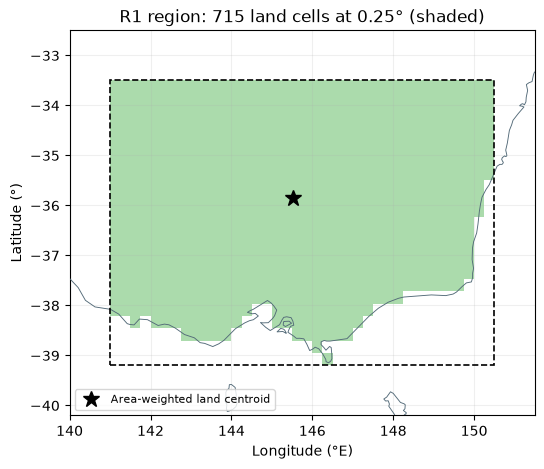

In [5]:
def region_axes(ax, pad=1.0):
    # Common map styling: limits, coastlines, region box, labels.
    ax.set_xlim(REGION['west'] - pad, REGION['east'] + pad)
    ax.set_ylim(REGION['south'] - pad, REGION['north'] + pad)
    viz.coastlines(ax, COAST_PATH)
    ax.add_patch(Rectangle((REGION['west'], REGION['south']), REGION['east'] - REGION['west'],
                           REGION['north'] - REGION['south'], fill=False, ec='k', lw=1.2, ls='--', zorder=6))
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°)')
    ax.set_aspect(1 / math.cos(math.radians(-36)))
    ax.grid(alpha=.2)

def cell_image(values, grid=GRID):
    # Reshape a per-cell vector to the (rows, cols) image; sea cells -> NaN.
    v = np.where(grid.land.values, values, np.nan)
    return v.reshape(grid.attrs['rows'], grid.attrs['cols'])

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.imshow(cell_image(np.ones(len(GRID))), extent=[REGION['west'], REGION['east'], REGION['south'], REGION['north']],
          origin='lower', cmap='Greens', vmin=0, vmax=2, alpha=.6, aspect='auto')
region_axes(ax)
ax.plot(LON_C, LAT_C, 'k*', ms=12, label='Area-weighted land centroid')
ax.legend(loc='lower left', fontsize=8)
ax.set_title(f'R1 region: {len(LAND)} land cells at {GRID_RES_DEG}° (shaded)')
save_fig(fig, 'region_grid'); plt.show()

## 4 · Orbit design: Sun-synchronous repeat orbits

### 4.1 Circular-orbit relations (Weeks 2–5)
For a circular orbit at altitude $h$:
$$a = R_E + h,\qquad n = \sqrt{\frac{\mu}{a^3}},\qquad T = \frac{2\pi}{n} = 2\pi\sqrt{\frac{a^3}{\mu}} .$$

### 4.2 $J_2$ nodal precession and the SSO condition (Weeks 6–8)
The first-order, orbit-averaged $J_2$ node rate for $e=0$ is
$$\dot\Omega = -\frac{3}{2}\,n\,J_2\left(\frac{R_E}{a}\right)^2\cos i .$$
A Sun-synchronous orbit sets this equal to the Sun's mean motion, $\dot\Omega_\text{req} = 360^\circ/T_\text{year} = +0.9856^\circ/\text{day}$, so
$$\cos i_\text{SSO} = -\frac{\dot\Omega_\text{req}}{\tfrac{3}{2}\,n\,J_2\,(R_E/a)^2}.$$
Because $\cos i<0$, the orbit is retrograde: $i_\text{SSO}\approx 97.4^\circ$ at 500 km (lecture worked example), and slightly more at higher altitude.

### 4.3 Ground-track clock and per-orbit shift (Week 8, Lecture 1)
The ground sees the difference between Earth rotation and nodal precession. For an ideal SSO this difference is exactly one revolution per mean solar day:
$$\omega_\oplus - \dot\Omega = \frac{360^\circ}{D_\text{sol}},\qquad
\Delta\lambda = -(\omega_\oplus-\dot\Omega)\,T = -360^\circ\frac{T}{D_\text{sol}},\qquad
d_\text{eq} = |\Delta\lambda|\frac{\pi}{180^\circ}R_E .$$

### 4.4 Exact-repeat condition and the repeat-orbit catalogue
A ground track repeats exactly after $j$ revolutions in $k$ nodal days ($j,k$ coprime):
$$jT = kD,\qquad D = \frac{2\pi}{\omega_\oplus-\dot\Omega} = D_\text{sol}\ (\text{ideal SSO})
\quad\Longrightarrow\quad T = \frac{kD_\text{sol}}{j},\qquad a = \left[\mu\left(\frac{T}{2\pi}\right)^2\right]^{1/3}.$$
After choosing $j/k$, we trim the altitude to $h=a-R_E$ and retune $i$ to $i_\text{SSO}(h)$. The cycle sets the equatorial track spacing $\Delta_\text{eq} = 2\pi R_E/j$ (Lecture 1 catalogue). Below, we rebuild the lecture's catalogue ($k\le 12$ days) with `eo.repeat_solution`.

**B0 rule (from D1):** the SSO repeat orbit *nearest the comparator's reference altitude*, $h_\text{ref}=600$ km (FireSat Protoflight), within the lecture catalogue ($k\le12$).

> **⚠️ CHECK A9** — 600 km is the D1 figure for FireSat Protoflight; confirm its actual altitude, inclination and LTAN from eoPortal/OSCAR.
>
> **⚠️ CHECK A16, A17, A19** — The $k\le12$ catalogue limit, the nearest-altitude rule (134/9 at 601.54 km vs 149/10 at 598.07 km) and the Keplerian (not nodal) period are choices or simplifications.

In [6]:
# ------------------------- Comparator / payload inputs ----------------------
H_COMPARATOR_KM   = 600.0    # FireSat Protoflight reference altitude [km] (D1 refs [1,2,6,7])  # CHECK A9
SWATH_COMPARATOR  = 1500.0   # comparator swath [km] at 600 km  # CHECK A10
GSD_NADIR_COMP_M  = 50.0     # MWIR nadir GSD at 600 km [m] (R2 nadir threshold)  # CHECK A11
GSD_MAX_ACCEPT_M  = 100.0    # R2: MWIR GSD at the maximum accepted view angle [m]  # CHECK A14
MAX_REPEAT_DAYS   = 12       # catalogue limit used in the Week 8 lecture  # CHECK A16

def circular(h_km, inc_deg):
    # a, n, T, node rate and ground-track numbers for a circular orbit (lecture eqns 4.1-4.3)
    o = eo.orbit_from_altitude(h_km, inc_deg)          # a, T, n, raan_dot [deg/day] ...
    shift = 360 * o['T'] / D_SOL                       # |Delta lambda| per rev for an SSO [deg]
    return dict(a_km=o['a'], T_s=o['T'], T_min=o['T'] / 60, revs_per_day=D_SOL / o['T'],
                raan_dot_deg_day=o['raan_dot'], shift_deg=shift,
                shift_eq_km=math.radians(shift) * R_E)

# Build the repeat catalogue: coprime j/k with k <= 12 and LEO altitudes (toolkit enforces 200-1500 km)
catalogue = []
for k in range(1, MAX_REPEAT_DAYS + 1):
    for j in range(10 * k, 17 * k + 1):
        if math.gcd(j, k) != 1:
            continue
        try:
            s = eo.repeat_solution(j, k)   # T = k D_sol / j, a from Kepler III, i_SSO(h)
        except ValueError:
            continue
        catalogue.append(dict(j=j, k=k, h_km=s['h_km'], inc_deg=s['inc_deg'], T_s=s['period_s'],
                              track_spacing_eq_km=2 * math.pi * R_E / j))
catalogue = pd.DataFrame(catalogue)
catalogue['dh_from_600_km'] = catalogue.h_km - H_COMPARATOR_KM

# B0: catalogue entry nearest 600 km
b0_row = catalogue.loc[catalogue.dh_from_600_km.abs().idxmin()]
print(f'B0 = {int(b0_row.j)} revolutions in {int(b0_row.k)} days, h = {b0_row.h_km:.3f} km '
      f'({b0_row.dh_from_600_km:+.2f} km from comparator), i = {b0_row.inc_deg:.4f}°')
display(catalogue.loc[catalogue.dh_from_600_km.abs().nsmallest(8).index]
        .round({'h_km': 2, 'inc_deg': 4, 'T_s': 2, 'track_spacing_eq_km': 1, 'dh_from_600_km': 2})
        .reset_index(drop=True))

B0 = 134 revolutions in 9 days, h = 601.540 km (+1.54 km from comparator), i = 97.7936°


,j,k,h_km,inc_deg,T_s,track_spacing_eq_km,dh_from_600_km
0,134,9,601.54,97.7936,5802.99,299.1,1.54
1,149,10,598.07,97.7799,5798.66,269.0,-1.93
2,164,11,595.23,97.7688,5795.12,244.4,-4.77
3,119,8,605.88,97.8106,5808.40,336.8,5.88
4,179,12,592.87,97.7595,5792.18,223.9,-7.13
5,104,7,611.48,97.8327,5815.38,385.3,11.48
6,89,6,618.96,97.8623,5824.72,450.3,18.96
7,163,11,623.73,97.8811,5830.67,245.9,23.73


### 4.5 Choosing B1: what repeat cycle can give access *every day*?

R1 asks each cell for an eligible access **every** day, not on average. Consider the eligible (afternoon, ascending) passes at latitude $\phi$:

* **One day's tracks** are spaced about $S = C_\phi/N$ along the parallel, where $C_\phi = 2\pi R_E\cos\phi$ and $N=j/k$ revolutions/day.
* **Over one repeat cycle** the $k$ daily patterns interleave to fill all $j$ tracks, spaced $\Delta = C_\phi/j = S/k$. This is the lecture's tiling spacing.

A cell at offset $x$ from a track sees, on successive days, nearest-track offsets $x, x+\Delta, x+2\Delta,\dots$ (mod $S$). Over the cycle these offsets fill the whole interval $[0,S)$ in steps of $\Delta$, so some day leaves the cell at least $(S-\Delta)/2$ from the nearest track. With usable swath width $W$ (measured along the parallel, the lecture's near-polar approximation), a cell can be reached every day only if
$$\frac{W}{2} \ge \frac{S-\Delta}{2}\quad\Longleftrightarrow\quad W \ \ge\ S\left(1-\frac{1}{k}\right).$$
This extends the lecture tiling condition $W\ge\Delta$ from "covered at some point in the cycle" to "covered *every day*".

* For $k\ge2$ this needs $W$ almost as large as the daily spacing $S$ ($\approx2200$ km at 36°S), roughly double our usable swath (§5). **Prediction: a $k=9$ orbit gives $F_\text{every}\approx0\%$**, whatever its phasing.
* For $k=1$ the condition is $W\ge0$: the daily strips **do not move**, so every cell inside a strip is reached every day. The question then becomes *where* the strip lies (phasing, §6), and whether the region fits inside it.

**B1 rule:** within the catalogue, take the 1-day repeat nearest B0's altitude. This is the D1 "trade between repeat days and altitude similarity": we accept the shortest possible cycle at the cost of a lower altitude.

> **⚠️ CHECK A18, A29** — B1 was not defined in D1. Choosing $k=1$ follows from the every-day metric (A4); a different metric or a constellation would change this choice.

,j,k,h_km,inc_deg,T_s,track_spacing_eq_km,dh_from_600_km,dh_from_B0
0,13,1,1262.224,100.725,6646.154,3082.627,662.224,660.684
1,14,1,893.929,99.007,6171.429,2862.440,293.929,292.389
2,15,1,567.031,97.659,5760.000,2671.610,-32.969,-34.510
3,16,1,274.553,96.583,5400.000,2504.635,-325.447,-326.987


B1 = 15 revolutions in 1 day, h = 567.031 km (-34.51 km from B0), i = 97.6587°


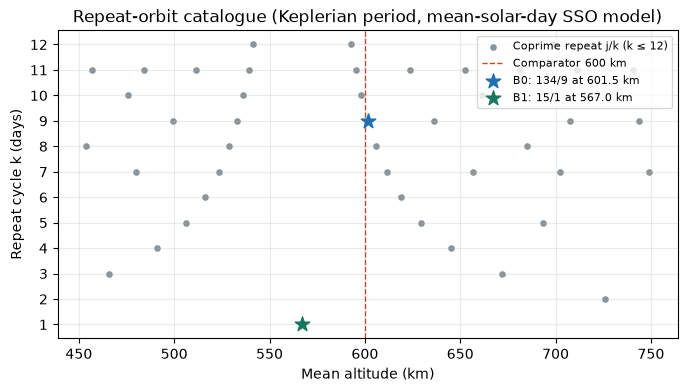

In [7]:
# B1: the 1-day repeat (k = 1) nearest B0's altitude
one_day = catalogue[catalogue.k == 1].copy()
one_day['dh_from_B0'] = one_day.h_km - b0_row.h_km
b1_row = one_day.loc[one_day.dh_from_B0.abs().idxmin()]
display(one_day.round(3).reset_index(drop=True))
print(f'B1 = {int(b1_row.j)} revolutions in {int(b1_row.k)} day, h = {b1_row.h_km:.3f} km '
      f'({b1_row.h_km - b0_row.h_km:+.2f} km from B0), i = {b1_row.inc_deg:.4f}°')

# Catalogue figure (lecture style): altitude vs repeat days, B0/B1 highlighted
fig, ax = plt.subplots(figsize=(8, 4))
near = catalogue[(catalogue.h_km > 450) & (catalogue.h_km < 750)]
ax.scatter(near.h_km, near.k, s=14, c='#8a939a', label='Coprime repeat j/k (k ≤ 12)')
ax.axvline(H_COMPARATOR_KM, color='#c74924', ls='--', lw=1, label='Comparator 600 km')
ax.scatter([b0_row.h_km], [b0_row.k], s=120, marker='*', c='#1f6fb2', zorder=5,
           label=f'B0: {int(b0_row.j)}/{int(b0_row.k)} at {b0_row.h_km:.1f} km')
ax.scatter([b1_row.h_km], [b1_row.k], s=120, marker='*', c='#197760', zorder=5,
           label=f'B1: {int(b1_row.j)}/{int(b1_row.k)} at {b1_row.h_km:.1f} km')
ax.set_xlabel('Mean altitude (km)'); ax.set_ylabel('Repeat cycle k (days)')
ax.set_yticks(range(1, MAX_REPEAT_DAYS + 1)); ax.grid(alpha=.25); ax.legend(fontsize=8, loc='upper right')
ax.set_title('Repeat-orbit catalogue (Keplerian period, mean-solar-day SSO model)')
save_fig(fig, 'repeat_catalogue'); plt.show()

## 5 · Payload geometry → maximum accepted view angle and usable swath

### 5.1 Earth-viewing geometry (Week 8, Lecture 2)
From the satellite, the Earth's angular radius is $\sin\rho = R_E/(R_E+h)$. For a target seen at nadir angle $\eta$, central angle $\gamma$ and elevation $\varepsilon$:
$$\sin\eta = \sin\rho\cos\varepsilon,\qquad \eta+\gamma+\varepsilon = 90^\circ,\qquad R_s = R_E\frac{\sin\gamma}{\sin\eta},\qquad d = R_E\,\gamma .$$
The incidence angle $\zeta$ at the ground satisfies $\sin\eta = \dfrac{R_E}{a}\sin\zeta$ (Week 10), so $\zeta = 90^\circ-\varepsilon$.

**Payload FOV.** The comparator images a 1500 km swath from 600 km. Its edge has $d=750$ km, so $\gamma = 750/R_E$ rad. Solving the triangle for the nadir angle gives
$$\tan\eta_\text{edge} = \frac{\sin\gamma}{a/R_E-\cos\gamma}.$$
B1 carries the *same payload*, so it keeps the same angular half-FOV $\eta_\text{edge}$. Its swath is recomputed at its own altitude.

### 5.2 Off-nadir sampling (Weeks 10–11)
With pitch $p$ and focal length $f$, $\text{IFOV}=p/f$ and nadir $\text{GSD}=h\,p/f$. Off nadir the sample is projected over the slant range $R_s$ and onto ground tilted by the incidence $\zeta$:
$$\text{GSD}_\text{along}(\eta) = \text{GSD}_0\frac{R_s}{h},\qquad
\text{GSD}_\text{cross}(\eta) = \frac{\text{GSD}_0}{\cos\zeta}\,\frac{R_s}{h} = \text{GSD}_0\frac{R_s}{h\,\sin\varepsilon}.$$
(`eo.off_nadir_gsd`; pure cross-track roll, flat local ground.) The same optics at a different altitude give $\text{GSD}_0(h) = \text{GSD}_0(600)\,h/600$.

### 5.3 Maximum accepted view angle (link to R2)
R2 accepts MWIR GSD $\le 100$ m. The **maximum accepted view angle** is therefore
$$\eta_\text{acc} = \min\big(\eta_\text{edge},\ \eta : \text{GSD}_\text{cross}(\eta)=100\ \text{m}\big),$$
found by bisection, because GSD grows monotonically with $\eta$. The **usable swath** is $W = 2R_E\,\gamma(\eta_\text{acc})$. Cells outside it can still be *seen* (the potential swath), but an access there would fail R2, so it is not eligible for R1.

> **⚠️ CHECK A10, A11, A13** — The 1500 km swath, 50 m MWIR nadir GSD and fixed-nadir pushbroom geometry are taken from D1's comparator sources and need confirming (which band the 50 m refers to; whether the instrument scans or points).
>
> **⚠️ CHECK A12, A14, A15** — The maximum accepted view angle was undefined in D1. It is set here from the *cross-track* GSD reaching 100 m, assuming the optics are unchanged between altitudes and flat local ground. Note the nadir-GSD flag printed below the payload table.

In [8]:
USE_R2_VIEW_LIMIT = True   # False -> eligibility uses the full geometric swath (potential access)  # CHECK A14

def half_fov_from_swath(h_km, swath_km):
    # Nadir angle of the swath edge: tan(eta) = sin(gamma) / (a/R_E - cos(gamma))
    gamma = (swath_km / 2) / R_E
    return math.degrees(math.atan2(math.sin(gamma), (R_E + h_km) / R_E - math.cos(gamma)))

def eta_for_gsd(h_km, gsd0_m, gsd_max_m, eta_hi_deg):
    # Bisection for the view angle where cross-track GSD reaches gsd_max (monotonic in eta)
    if eo.off_nadir_gsd(h_km, gsd0_m, eta_hi_deg)['gsd_cross_m'] <= gsd_max_m:
        return eta_hi_deg
    lo, hi = 0.0, eta_hi_deg
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        if eo.off_nadir_gsd(h_km, gsd0_m, mid)['gsd_cross_m'] <= gsd_max_m:
            lo = mid
        else:
            hi = mid
    return lo

ETA_EDGE = half_fov_from_swath(H_COMPARATOR_KM, SWATH_COMPARATOR)   # payload half-FOV [deg], fixed hardware
print(f'Payload half-FOV from 1500 km swath at 600 km: eta_edge = {ETA_EDGE:.3f}°  (full FOV {2*ETA_EDGE:.2f}°)')

def payload_geometry(h_km):
    # All altitude-dependent imaging quantities that feed R1 eligibility
    gsd0 = GSD_NADIR_COMP_M * h_km / H_COMPARATOR_KM                  # GSD = h p / f, same optics  # CHECK A12
    eta_gsd = eta_for_gsd(h_km, gsd0, GSD_MAX_ACCEPT_M, ETA_EDGE)
    eta_acc = min(ETA_EDGE, eta_gsd) if USE_R2_VIEW_LIMIT else ETA_EDGE
    g_acc = eo.access_geometry(h_km, eta_deg=eta_acc)                  # rho, gamma, eps, R_s, reach
    g_edge = eo.access_geometry(h_km, eta_deg=ETA_EDGE)
    edge_gsd = eo.off_nadir_gsd(h_km, gsd0, ETA_EDGE)
    return dict(h_km=h_km, rho_deg=g_acc['rho'], gsd_nadir_m=gsd0,
                eta_edge_deg=ETA_EDGE, full_swath_km=2 * g_edge['ground_reach'],
                gsd_cross_at_edge_m=edge_gsd['gsd_cross_m'],
                eta_gsd100_deg=eta_gsd, eta_acc_deg=eta_acc,
                eps_at_eta_acc_deg=g_acc['eps'], incidence_at_eta_acc_deg=90 - g_acc['eps'],
                slant_at_eta_acc_km=g_acc['R_s'], reach_km=g_acc['ground_reach'],
                usable_swath_km=2 * g_acc['ground_reach'])

PAY = {'B0': payload_geometry(b0_row.h_km), 'B1': payload_geometry(b1_row.h_km)}
pay_df = pd.DataFrame(PAY)
display(pay_df.round(3))
# CHECK A12: flag any configuration whose scaled nadir GSD breaks R2's nadir threshold (50 m)
for cfg, p in PAY.items():
    if p['gsd_nadir_m'] > GSD_NADIR_COMP_M:
        print(f"⚠️ CHECK A12: {cfg} nadir GSD = {p['gsd_nadir_m']:.3f} m exceeds the R2 nadir threshold of "
              f"{GSD_NADIR_COMP_M:.0f} m by {p['gsd_nadir_m'] - GSD_NADIR_COMP_M:.3f} m (linear altitude scaling).")
save_table(pay_df, 'payload_geometry')

Payload half-FOV from 1500 km swath at 600 km: eta_edge = 49.281°  (full FOV 98.56°)


,B0,B1
h_km,601.540,567.031
rho_deg,66.038,66.687
gsd_nadir_m,50.128,47.253
eta_edge_deg,49.281,49.281
full_swath_km,1504.179,1411.045
gsd_cross_at_edge_m,147.678,137.091
eta_gsd100_deg,41.231,42.874
eta_acc_deg,41.231,42.874
eps_at_eta_acc_deg,43.842,42.193
incidence_at_eta_acc_deg,46.158,47.807


⚠️ CHECK A12: B0 nadir GSD = 50.128 m exceeds the R2 nadir threshold of 50 m by 0.128 m (linear altitude scaling).


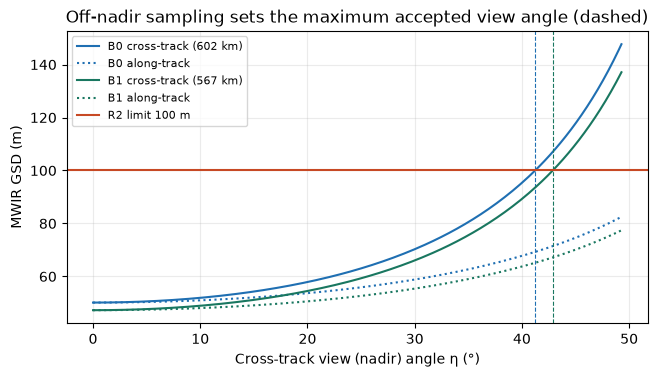

In [9]:
# GSD vs view angle for both altitudes, showing where 100 m is reached
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for cfg, col in [('B0', '#1f6fb2'), ('B1', '#197760')]:
    h = PAY[cfg]['h_km']; g0 = PAY[cfg]['gsd_nadir_m']
    eta = np.linspace(0, ETA_EDGE, 200)
    cross = [eo.off_nadir_gsd(h, g0, e)['gsd_cross_m'] for e in eta]
    along = [eo.off_nadir_gsd(h, g0, e)['gsd_along_m'] for e in eta]
    ax.plot(eta, cross, color=col, label=f'{cfg} cross-track ({h:.0f} km)')
    ax.plot(eta, along, color=col, ls=':', label=f'{cfg} along-track')
    ax.axvline(PAY[cfg]['eta_acc_deg'], color=col, lw=.8, ls='--')
ax.axhline(GSD_MAX_ACCEPT_M, color='#c74924', label='R2 limit 100 m')
ax.set_xlabel('Cross-track view (nadir) angle η (°)'); ax.set_ylabel('MWIR GSD (m)')
ax.set_title('Off-nadir sampling sets the maximum accepted view angle (dashed)')
ax.grid(alpha=.25); ax.legend(fontsize=8)
save_fig(fig, 'gsd_vs_view_angle'); plt.show()

## 6 · Local time of the node (LTAN, $T_0$) and phasing

### 6.1 Local time of a pass
LTAN is the local mean solar time of the northbound equator crossing (Lecture 1). In a frame that turns with the mean Sun, an ideal SSO plane does not move. A point on the orbit at argument of latitude $u$ is then displaced in right ascension from the node by
$$\Delta\alpha(u) = \operatorname{atan2}\!\big(\cos i\,\sin u,\ \cos u\big),\qquad \sin u = \frac{\sin\phi}{\sin i}\ \ (\text{ascending branch: } |u|<90^\circ),$$
and its sub-satellite local mean solar time is
$$\text{LMST}_\text{SSP}(\phi) = \text{LTAN} + \frac{\Delta\alpha(u)}{15^\circ/\text{h}} .$$
A cell displaced cross-track from the track has its own longitude, so its local time differs by about $\pm(\text{cross-track offset in longitude})/15$. For a given LTAN, the eligible passes over the region therefore form a fixed band of local times. The descending passes fall about 12 h later and are excluded by the window.

### 6.2 Choosing $T_0$
Shifting the LTAN shifts every pass time by the same amount, so the offsets $\text{LMST}-\text{LTAN}$ do not depend on it. We compute those offsets on a coarse grid and then centre the band of eligible pass times in the fire window:
$$T_0 = \frac{t_\text{open}+t_\text{close}}{2} - \frac{\min(\text{offset})+\max(\text{offset})}{2},$$
rounded to the nearest 15 min. B1 keeps the same $T_0$ (D1 design rule).

### 6.3 Initial elements at the epoch (model frame)
The model frame has Greenwich on its $x$-axis at the epoch (Lecture 7: $\theta_G(t_0)$ chosen with the epoch). At 00:00 UTC the LMST at longitude $\lambda$ is $\lambda/15$ h, so the node's model RAAN is
$$\Omega_0 = 15^\circ/\text{h}\times T_0 .$$
**Phasing.** We set the argument of latitude $u_0$ so that the *first* afternoon pass over the land centroid $(\phi_c,\lambda_c)$ passes straight overhead. The node's Earth-fixed longitude drifts as $\lambda_\text{node}(t)=\Omega_0+(\dot\Omega-\omega_\oplus)t$. We solve
$$\lambda_\text{node}(t_c) + \Delta\alpha(u_c) = \lambda_c \ \text{ for } t_c\in[0,1\ \text{day}),\qquad u_0 = u_c - n\,t_c .$$
Both designs use the same rule, so neither is favoured by placement. For B0 the strip then moves each day; for B1 it stays where it was placed.

> **⚠️ CHECK A20** — LTAN 15:15 (ascending) is a design choice made by centring the passes in the window. A wide range of LTANs also works (printed in §7.3), and power/thermal/eclipse effects are not assessed. FireSat's actual LTAN (A9) may motivate a different value.
>
> **⚠️ CHECK A21** — Centroid phasing assumes the along-track phase can be set at commissioning and held; B1's result depends on it.

In [10]:
@dataclass(frozen=True)
class Orbit:
    # Circular SSO in the epoch-Greenwich model frame. Angles in degrees at the interface.
    name: str
    h_km: float
    inc_deg: float
    raan0_deg: float = 0.0     # model RAAN at epoch (= Earth-fixed node longitude at t=0)
    u0_deg: float = 0.0        # argument of latitude at epoch
    j: int = 0                 # revolutions per repeat cycle (bookkeeping)
    k: int = 0                 # days per repeat cycle

    @property
    def a(self): return R_E + self.h_km
    @property
    def n(self): return math.sqrt(MU / self.a**3)                    # rad/s
    @property
    def T(self): return 2 * math.pi / self.n                           # s
    @property
    def raan_dot(self):                                                # rad/s, first-order J2
        return -1.5 * self.n * J2 * (R_E / self.a)**2 * math.cos(math.radians(self.inc_deg))

def delta_alpha_deg(lat_deg, inc_deg):
    # Right-ascension offset of the ascending-branch SSP from the node at latitude lat
    i = math.radians(inc_deg)
    u = math.asin(math.sin(math.radians(lat_deg)) / math.sin(i))
    return math.degrees(math.atan2(math.cos(i) * math.sin(u), math.cos(u))), math.degrees(u)

def phased_orbit(name, h_km, inc_deg, ltan_h, lat_c, lon_c, j=0, k=0):
    # Orbit with RAAN set by the LTAN and phase set so the first ascending pass is over (lat_c, lon_c)
    trial = Orbit(name, h_km, inc_deg)
    raan0 = (15.0 * ltan_h) % 360.0
    dalpha, u_c = delta_alpha_deg(lat_c, inc_deg)
    rate = math.degrees(trial.raan_dot - OMEGA_E)                      # deg/s (negative: node drifts west)
    turn = 360.0 / abs(rate)                                           # = one mean solar day for an SSO
    t_c = (((lon_c - dalpha - raan0) % 360.0) - 360.0) / rate % turn   # first time in [0, 1 day)
    u0 = (u_c - math.degrees(trial.n) * t_c) % 360.0
    return Orbit(name, h_km, inc_deg, raan0, u0, j, k), t_c

## 7 · Access model: when does a pushbroom image a cell?

### 7.1 State in the Earth-fixed frame (Week 7 ground-track algorithm)
For a circular orbit, the Earth-fixed position unit vector $\hat q$ follows from the 3-1-3 rotation of the perifocal position, with the node measured from Greenwich:
$$\lambda_\text{node}(t) = \Omega_0 + (\dot\Omega-\omega_\oplus)\,t,\qquad u(t)=u_0+n\,t,$$
$$\hat q = \begin{bmatrix}\cos\lambda_\text{node}\cos u - \sin\lambda_\text{node}\cos i\sin u\\ \sin\lambda_\text{node}\cos u + \cos\lambda_\text{node}\cos i\sin u\\ \sin i\sin u\end{bmatrix},\qquad
\hat x = \frac{\partial\hat q}{\partial u},\qquad \hat y = -\hat q\times\hat x .$$
Here $\hat x$ is the along-track axis, $\hat y$ the cross-track axis and $-\hat q$ nadir. These are the same axes as the tutorial's `eo_access_design.state` (no yaw steering).

### 7.2 Imaging event
The line of sight to a cell with unit vector $\hat t$ is $\boldsymbol\ell = R_E\hat t - a\hat q$. A pushbroom with a thin along-track field images the cell when its along-track component is zero:
$$g(t) = \boldsymbol\ell\cdot\hat x = R_E\,\hat t\cdot\hat x(t) = 0,\qquad \text{near side: } \hat q\cdot\hat t>0 .$$
We bracket the roots of $g$ on a coarse time grid (step $\Delta t \le T/32$, as the tutorial requires) and refine all of them at once by bisection to 1 ms. At each event:
$$\eta = \operatorname{atan2}\big(|\boldsymbol\ell\cdot\hat y|,\ -\boldsymbol\ell\cdot\hat q\big),\qquad
\varepsilon = \arcsin\!\left(-\frac{\boldsymbol\ell}{|\boldsymbol\ell|}\cdot\hat t\right),\qquad
\text{LMST} = \frac{t}{3600} + \frac{\lambda}{15}\ (\text{mod } 24).$$
The event is **eligible** if $\eta\le\eta_\text{acc}$, $\varepsilon>0$ and the LMST is inside the window. The local day index is $\lfloor(t/3600+\lambda/15)/24\rfloor$.

*Why events rather than windows:* the along-track FOV of a pushbroom is very thin, so the tutorial's finite "windows" shrink to instants. Each event is one possible MWIR acquisition of that cell.

> **⚠️ CHECK A13, A24** — The event model assumes a fixed pushbroom with no yaw steering, on a circular orbit with secular J₂ only and no drag.

In [11]:
def unit_vector(lat_deg, lon_deg):
    # ECEF unit vector of a ground point on the sphere
    la, lo = np.radians(lat_deg), np.radians(lon_deg)
    return np.stack((np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)), axis=-1)

def state(orb, t):
    # Earth-fixed radial unit vector q, along-track x, cross-track y and argument of latitude u
    t = np.asarray(t, float)
    u = math.radians(orb.u0_deg) + orb.n * t
    lam = math.radians(orb.raan0_deg) + (orb.raan_dot - OMEGA_E) * t     # node longitude
    ci, si = math.cos(math.radians(orb.inc_deg)), math.sin(math.radians(orb.inc_deg))
    cu, su, cl, sl = np.cos(u), np.sin(u), np.cos(lam), np.sin(lam)
    q = np.stack((cl * cu - sl * ci * su, sl * cu + cl * ci * su, si * su), axis=-1)
    x = np.stack((-cl * su - sl * ci * cu, -sl * su + cl * ci * cu, si * cu), axis=-1)
    y = np.cross(-q, x)
    return q, x, y, u

_COARSE = {}
def coarse_states(orb, horizon_s, step_s):
    # Cache the coarse-grid states: shared by every cell for one orbit/step
    key = (orb, horizon_s, step_s)
    if key not in _COARSE:
        if step_s > orb.T / 32:
            raise ValueError('Use step <= T/32 (tutorial bracketing rule)')
        t = np.arange(horizon_s[0], horizon_s[1] + step_s, step_s)
        q, x, _, _ = state(orb, t)
        _COARSE.clear()                      # keep memory bounded: one orbit at a time
        _COARSE[key] = (t, q, x)
    return _COARSE[key]

def imaging_events(orb, lat, lon, horizon_s=HORIZON_S, step_s=30.0, tol_s=1e-3):
    # All near-side pushbroom imaging instants of one ground cell, with their geometry
    t, q, x = coarse_states(orb, horizon_s, step_s)
    tgt = unit_vector(lat, lon)
    g = x @ tgt                              # along-track component (scaled) on the coarse grid
    near = q @ tgt                           # > 0 on the visible hemisphere
    k = np.flatnonzero((g[:-1] * g[1:] < 0) & (near[:-1] > 0))
    a, b, ga = t[k].copy(), t[k + 1].copy(), g[k].copy()
    while k.size and np.max(b - a) > tol_s:  # vectorised bisection on every bracket at once
        m = 0.5 * (a + b)
        gm = state(orb, m)[1] @ tgt
        same = np.sign(gm) == np.sign(ga)
        a = np.where(same, m, a); ga = np.where(same, gm, ga)
        b = np.where(same, b, m)
    te = 0.5 * (a + b)
    q, x, y, u = state(orb, te)
    los = R_E * tgt - orb.a * q                                       # line of sight
    rng = np.linalg.norm(los, axis=-1)
    eta = np.degrees(np.arctan2(np.abs(np.sum(los * y, -1)), -np.sum(los * q, -1)))
    eps = np.degrees(np.arcsin(np.clip(np.sum(-los / rng[:, None] * tgt, -1), -1, 1)))
    ssp_lon = np.degrees(np.arctan2(q[:, 1], q[:, 0]))
    east = ((lon - ssp_lon + 180) % 360 - 180) >= 0                    # cell east of the track?
    hours = te / 3600 + lon / 15
    return pd.DataFrame(dict(t_s=te, eta_deg=eta, elev_deg=eps, slant_km=rng,
                             ascending=np.cos(u) > 0, lmst_h=hours % 24,
                             local_day=np.floor(hours / 24).astype(int),
                             cross_km=np.where(east, 1, -1) * R_E * np.radians(90 - eta - eps)))

In [12]:
def evaluate_r1(orb, eta_acc_deg, grid=GRID, step_s=30.0, window=FIRE_WINDOW_LMST_H, keep_events=True):
    # Run the R1 test over all land cells; returns per-cell, per-day and summary results
    land = grid[grid.land]
    area = land.area_km2.values
    days_hit = np.zeros((len(land), N_DAYS), bool)
    n_events, all_events = 0, []
    for c, (lat, lon) in enumerate(zip(land.latitude_deg.values, land.longitude_deg.values)):
        ev = imaging_events(orb, lat, lon, step_s=step_s)
        geo_ok = (ev.eta_deg <= eta_acc_deg) & (ev.elev_deg > 0)
        in_win = (ev.lmst_h >= window[0]) & (ev.lmst_h <= window[1])
        ok = geo_ok & in_win & (ev.local_day >= 0) & (ev.local_day < N_DAYS)
        days_hit[c, ev.local_day[ok].values] = True
        n_events += len(ev)
        if keep_events:
            ev = ev.assign(cell=land.index[c], geo_ok=geo_ok, eligible=ok)
            all_events.append(ev)
    every = days_hit.all(axis=1)                                   # reached on all 90 days
    frac_days = days_hit.mean(axis=1)
    # Longest run of consecutive local days without eligible access, per cell
    def longest_miss(row):
        best = run = 0
        for hit in row:
            run = 0 if hit else run + 1
            best = max(best, run)
        return best
    miss_run = np.array([longest_miss(r) for r in days_hit])
    daily_pct = 100 * (days_hit * area[:, None]).sum(0) / area.sum()
    F_every = 100 * area[every].sum() / area.sum()
    res = dict(orbit=orb, eta_acc_deg=eta_acc_deg, step_s=step_s, grid_res=grid.attrs['res'],
               land_index=land.index.values, days_hit=days_hit, every=every, frac_days=frac_days,
               miss_run=miss_run, daily_pct=daily_pct, n_events=n_events,
               F_every_pct=F_every, margin_pp=F_every - REQUIRED_PCT,
               verdict='met' if F_every >= REQUIRED_PCT else 'unmet',
               mean_frac_days=float(np.average(frac_days, weights=area)))
    if keep_events:
        res['events'] = pd.concat(all_events, ignore_index=True)
    return res

### 7.3 Fix $T_0$, then build B0 and B1
We run a quick provisional pass on a 1° grid with a trial LTAN to get the pass-time offsets, then set $T_0$ by the centring rule in §6.2.

In [13]:
LTAN_TRIAL_H = 15.0   # trial value only; final LTAN set by the centring rule  # CHECK A20
coarse_grid = make_grid(1.0)
offsets = []
for row, lab in [(b0_row, 'B0'), (b1_row, 'B1')]:
    trial, _ = phased_orbit(lab, row.h_km, row.inc_deg, LTAN_TRIAL_H, LAT_C, LON_C)
    for lat, lon in coarse_grid[coarse_grid.land][['latitude_deg', 'longitude_deg']].values:
        ev = imaging_events(trial, lat, lon, horizon_s=(0.0, 3 * D_SOL))
        ev = ev[(ev.eta_deg <= PAY[lab]['eta_acc_deg']) & (ev.elev_deg > 0) & ev.ascending]
        offsets.extend(((ev.lmst_h - LTAN_TRIAL_H + 12) % 24 - 12).tolist())
offsets = np.array(offsets)
centre = 0.5 * sum(FIRE_WINDOW_LMST_H)
LTAN_H = round((centre - 0.5 * (offsets.min() + offsets.max())) * 4) / 4      # nearest 15 min
print(f'Eligible ascending-pass LMST offsets from LTAN: {60*offsets.min():+.1f} to {60*offsets.max():+.1f} min')
print(f'Window centre {hhmm(centre)}  ->  T0 = LTAN = {hhmm(LTAN_H)} LMST (ascending node)')
lo_ltan = FIRE_WINDOW_LMST_H[0] - offsets.min(); hi_ltan = FIRE_WINDOW_LMST_H[1] - offsets.max()
print(f'⚠️ CHECK A20: any LTAN from {hhmm(lo_ltan)} to {hhmm(hi_ltan)} keeps every eligible pass inside the window')
print(f'Predicted pass band {hhmm(LTAN_H + offsets.min())}–{hhmm(LTAN_H + offsets.max())}, margins to window '
      f'{60*(LTAN_H + offsets.min() - FIRE_WINDOW_LMST_H[0]):.0f} min (open) / '
      f'{60*(FIRE_WINDOW_LMST_H[1] - LTAN_H - offsets.max()):.0f} min (close)')

Eligible ascending-pass LMST offsets from LTAN: +5.8 to +47.4 min
Window centre 15:45  ->  T0 = LTAN = 15:15 LMST (ascending node)
⚠️ CHECK A20: any LTAN from 12:54 to 17:43 keeps every eligible pass inside the window
Predicted pass band 15:21–16:02, margins to window 141 min (open) / 148 min (close)


In [14]:
# Final orbits (same LTAN, same centroid-phasing rule)
B0, tc0 = phased_orbit('B0', b0_row.h_km, b0_row.inc_deg, LTAN_H, LAT_C, LON_C, int(b0_row.j), int(b0_row.k))
B1, tc1 = phased_orbit('B1', b1_row.h_km, b1_row.inc_deg, LTAN_H, LAT_C, LON_C, int(b1_row.j), int(b1_row.k))
ORBITS = {'B0': B0, 'B1': B1}

def orbit_table():
    rows = {}
    for lab, o in ORBITS.items():
        c = circular(o.h_km, o.inc_deg)
        tc = tc0 if lab == 'B0' else tc1
        rows[lab] = {
            'Repeat: revolutions N / days D': f'{o.j} / {o.k}',
            'Altitude h (km)': round(o.h_km, 3),
            'Semi-major axis a (km)': round(c['a_km'], 3),
            'Inclination i (deg, SSO)': round(o.inc_deg, 4),
            'Eccentricity': 0,
            'Period T (min)': round(c['T_min'], 4),
            'Revs per day': round(c['revs_per_day'], 4),
            'Node rate (deg/day)': round(c['raan_dot_deg_day'], 4),
            'Per-orbit shift (deg W / km at equator)': f"{c['shift_deg']:.3f} / {c['shift_eq_km']:.0f}",
            'Equatorial track spacing 2πR/N (km)': round(2 * math.pi * R_E / o.j, 1),
            'LTAN T0 (LMST, ascending)': hhmm(LTAN_H),
            'Epoch': EPOCH_UTC.strftime('%Y-%m-%d %H:%M UTC'),
            'Model RAAN at epoch (deg, Greenwich frame)': round(o.raan0_deg, 3),
            'Argument of latitude at epoch u0 (deg)': round(o.u0_deg, 3),
            'First centroid pass (UTC)': (EPOCH_UTC + timedelta(seconds=tc)).strftime('%Y-%m-%d %H:%M:%S'),
            'Nadir MWIR GSD (m)': round(PAY[lab]['gsd_nadir_m'], 2),
            'Max accepted view angle eta_acc (deg)': round(PAY[lab]['eta_acc_deg'], 3),
            'Usable swath W (km)': round(PAY[lab]['usable_swath_km'], 1),
            'Full geometric swath (km)': round(PAY[lab]['full_swath_km'], 1),
        }
    return pd.DataFrame(rows)

ORBIT_TABLE = orbit_table()
display(ORBIT_TABLE)
save_table(ORBIT_TABLE, 'orbit_definitions')

,B0,B1
Repeat: revolutions N / days D,134 / 9,15 / 1
Altitude h (km),601.54,567.031
Semi-major axis a (km),6979.54,6945.031
"Inclination i (deg, SSO)",97.7936,97.6587
Eccentricity,0,0
Period T (min),96.7164,96.0
Revs per day,14.8889,15.0
Node rate (deg/day),0.9857,0.9857
Per-orbit shift (deg W / km at equator),24.179 / 2692,24.000 / 2672
Equatorial track spacing 2πR/N (km),299.1,2671.6


**Model check: does the LTAN stay fixed through the season?** The ascending-node times are $t_m = (2\pi m - u_0)/n$. At each node crossing the LMST at the sub-satellite longitude must equal $T_0$ if the SSO inclination and Earth-rotation clock are consistent.

In [15]:
for lab, o in ORBITS.items():
    m = np.arange(math.ceil(math.radians(o.u0_deg) / (2 * math.pi)) + 1,
                  math.floor((math.radians(o.u0_deg) + o.n * HORIZON_S[1]) / (2 * math.pi)))
    t_nodes = (2 * math.pi * m - math.radians(o.u0_deg)) / o.n
    q = state(o, t_nodes)[0]
    lmst = (t_nodes / 3600 + np.degrees(np.arctan2(q[:, 1], q[:, 0])) / 15) % 24
    print(f'{lab}: {len(t_nodes)} node crossings, LMST at node = {hhmm(lmst.min())}…{hhmm(lmst.max())} '
          f'(spread {3600*(lmst.max()-lmst.min()):.2e} s)')

B0: 1338 node crossings, LMST at node = 15:15…15:15 (spread 5.73e-09 s)
B1: 1348 node crossings, LMST at node = 15:15…15:15 (spread 6.55e-09 s)


## 8 · R1 results: B0 vs B1

Both designs are evaluated with the same grid, horizon, window and eligibility rules. Only the orbit, and the orbit-dependent GSD/view-angle limit, change. This keeps the comparison controlled.

In [16]:
RESULTS = {}
for lab, o in ORBITS.items():
    t0 = time.time()
    RESULTS[lab] = evaluate_r1(o, PAY[lab]['eta_acc_deg'])
    print(f'{lab}: {RESULTS[lab]["n_events"]:,} imaging events over {len(LAND)} cells in {time.time()-t0:.1f} s')

def summary_row(lab, r):
    ev = r['events']; el = ev[ev.eligible]
    return {'Configuration': lab,
            'Orbit': f"{r['orbit'].j}/{r['orbit'].k} @ {r['orbit'].h_km:.1f} km",
            'eta_acc (deg)': round(r['eta_acc_deg'], 3),
            'F_every: land area reached every day (%)': r['F_every_pct'],
            'Required (%)': REQUIRED_PCT,
            'Margin (pp)': r['margin_pp'],
            'Verdict': r['verdict'],
            'Daily regional fraction: worst day (%)': r['daily_pct'].min(),
            'Daily regional fraction: mean (%)': r['daily_pct'].mean(),
            'Mean fraction of days per cell (%)': 100 * r['mean_frac_days'],
            'Longest no-access run, worst cell (days)': int(r['miss_run'].max()),
            'Eligible-pass LMST range': f"{hhmm(el.lmst_h.min())}–{hhmm(el.lmst_h.max())}" if len(el) else 'none',
            'Geometric passes rejected by time window': int((ev.geo_ok & ~ev.eligible).sum())}

SUMMARY = pd.DataFrame([summary_row(l, r) for l, r in RESULTS.items()]).set_index('Configuration')
with pd.option_context('display.float_format', '{:.4f}'.format):
    display(SUMMARY.T)
save_table(SUMMARY.T, 'R1_summary')

B0: 958,100 imaging events over 715 cells in 12.7 s
B1: 965,250 imaging events over 715 cells in 7.2 s


Configuration,B0,B1
Orbit,134/9 @ 601.5 km,15/1 @ 567.0 km
eta_acc (deg),41.2310,42.8740
F_every: land area reached every day (%),0.0000,100.0000
Required (%),90.0000,90.0000
Margin (pp),-90.0000,10.0000
Verdict,unmet,met
Daily regional fraction: worst day (%),2.6063,100.0000
Daily regional fraction: mean (%),51.4036,100.0000
Mean fraction of days per cell (%),51.4036,100.0000
"Longest no-access run, worst cell (days)",5,0


In [17]:
# Scoped verdict text (unrounded comparison, rounded display)
for lab, r in RESULTS.items():
    display(Markdown(
        f"**{lab}** ({r['orbit'].j} revs / {r['orbit'].k} d, h = {r['orbit'].h_km:.2f} km, LTAN {hhmm(LTAN_H)}): "
        f"$F_\\text{{every}}$ = {r['F_every_pct']:.2f} % vs ≥ {REQUIRED_PCT:.0f} % → margin "
        f"**{r['margin_pp']:+.2f} pp, {r['verdict'].upper()}** within the stated model "
        f"(eligible geometric access, {GRID_RES_DEG}° land grid, {EPOCH_UTC.date()} + {N_DAYS} d)."))

**B0** (134 revs / 9 d, h = 601.54 km, LTAN 15:15): $F_\text{every}$ = 0.00 % vs ≥ 90 % → margin **-90.00 pp, UNMET** within the stated model (eligible geometric access, 0.25° land grid, 2026-12-01 + 90 d).

**B1** (15 revs / 1 d, h = 567.03 km, LTAN 15:15): $F_\text{every}$ = 100.00 % vs ≥ 90 % → margin **+10.00 pp, MET** within the stated model (eligible geometric access, 0.25° land grid, 2026-12-01 + 90 d).

### 8.1 Ground tracks and usable swaths over the region
The tracks below are the eligible (afternoon, ascending) passes for the first $k_{B0}=9$ days, shown as centreline plus usable-swath edges. B0's strip lands somewhere new each day and only covers the whole region after 9 days. B1's 1-day repeat puts the strip in the same place every day.

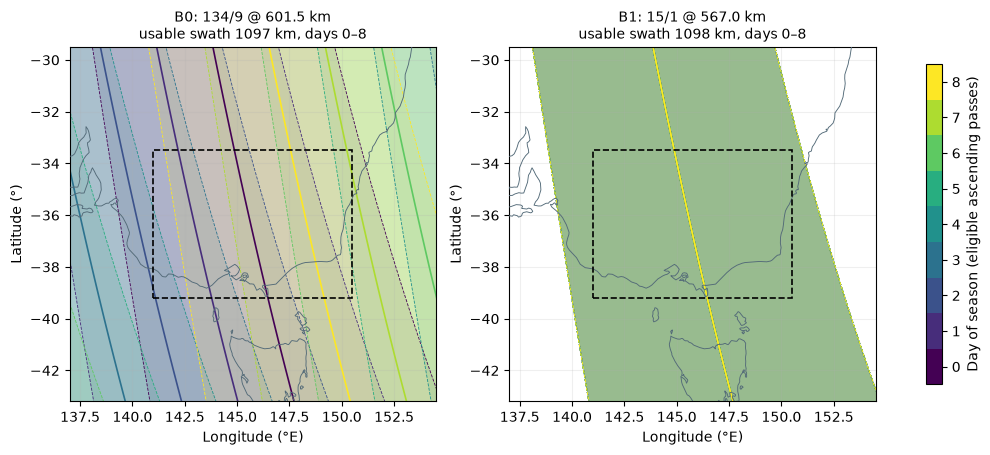

In [18]:
def pass_strips(orb, reach_km, days, step_s=10.0):
    # Ascending-pass centrelines and usable-swath edges near the region, split into separate passes
    t = np.arange(0, days * D_SOL, step_s)
    q, x, y, u = state(orb, t)
    gam = reach_km / R_E
    lat = lambda v: np.degrees(np.arcsin(np.clip(v[:, 2], -1, 1)))
    lon = lambda v: np.degrees(np.arctan2(v[:, 1], v[:, 0]))
    centre, left, right = (q, q * math.cos(gam) + y * math.sin(gam), q * math.cos(gam) - y * math.sin(gam))
    keep = (np.cos(u) > 0) & (lat(centre) > -48) & (lat(centre) < -25) & (lon(centre) > 125) & (lon(centre) < 170)
    idx = np.flatnonzero(keep)
    runs = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
    out = []
    for r in runs:
        if len(r) < 3: continue
        out.append(dict(day=int(t[r[0]] // D_SOL),
                        c=np.column_stack([lon(centre[r]), lat(centre[r])]),
                        l=np.column_stack([lon(left[r]), lat(left[r])]),
                        rt=np.column_stack([lon(right[r]), lat(right[r])])))
    return out

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
cmap = plt.get_cmap('viridis', 9)
for ax, (lab, o) in zip(axes, ORBITS.items()):
    for s in pass_strips(o, PAY[lab]['reach_km'], days=9):
        col = cmap(s['day'])
        ax.add_patch(Polygon(np.vstack([s['l'], s['rt'][::-1]]), closed=True, fc=col, ec='none', alpha=.12))
        ax.plot(*s['c'].T, color=col, lw=1.2)
        ax.plot(*s['l'].T, color=col, lw=.6, ls='--'); ax.plot(*s['rt'].T, color=col, lw=.6, ls='--')
    region_axes(ax, pad=4)
    ax.set_title(f"{lab}: {o.j}/{o.k} @ {o.h_km:.1f} km\nusable swath {PAY[lab]['usable_swath_km']:.0f} km, days 0–8", fontsize=10)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-.5, 8.5))
fig.colorbar(sm, ax=axes, ticks=range(9), label='Day of season (eligible ascending passes)', shrink=.8)
save_fig(fig, 'ground_tracks_swaths'); plt.show()

### 8.2 Where and how often each cell is reached

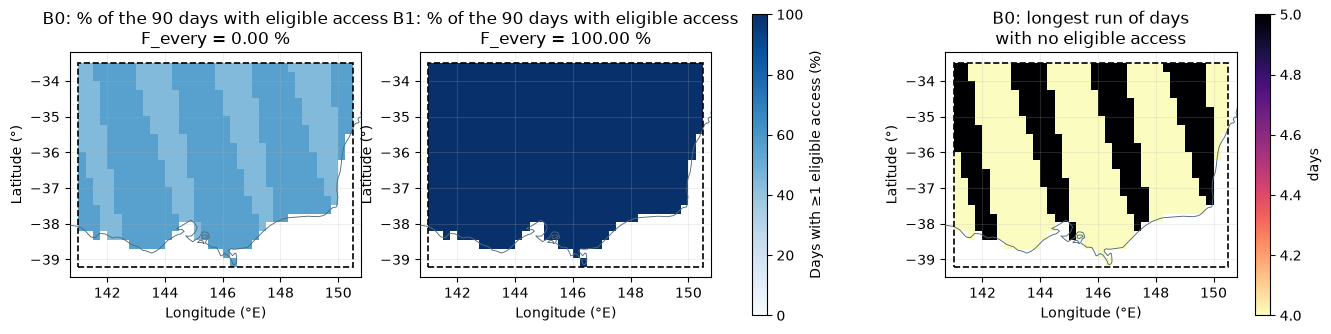

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ext = [REGION['west'], REGION['east'], REGION['south'], REGION['north']]
for ax, lab in zip(axes[:2], RESULTS):
    r = RESULTS[lab]
    v = np.full(len(GRID), np.nan); v[GRID.index.get_indexer(r['land_index'])] = 100 * r['frac_days']
    im = ax.imshow(cell_image(v), extent=ext, origin='lower', cmap='Blues', vmin=0, vmax=100, aspect='auto')
    region_axes(ax, pad=.3)
    ax.set_title(f"{lab}: % of the 90 days with eligible access\nF_every = {r['F_every_pct']:.2f} %")
fig.colorbar(im, ax=axes[:2], label='Days with ≥1 eligible access (%)', shrink=.85)
r = RESULTS['B0']
v = np.full(len(GRID), np.nan); v[GRID.index.get_indexer(r['land_index'])] = r['miss_run']
im2 = axes[2].imshow(cell_image(v), extent=ext, origin='lower', cmap='magma_r', aspect='auto')
region_axes(axes[2], pad=.3); axes[2].set_title('B0: longest run of days\nwith no eligible access')
fig.colorbar(im2, ax=axes[2], label='days', shrink=.85)
save_fig(fig, 'cell_access_maps'); plt.show()

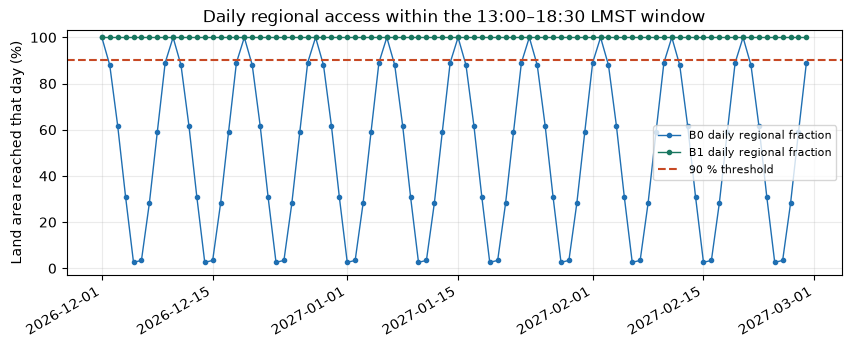

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.6))
dates = [EPOCH_UTC.date() + timedelta(days=d) for d in range(N_DAYS)]
for lab, col in [('B0', '#1f6fb2'), ('B1', '#197760')]:
    ax.plot(dates, RESULTS[lab]['daily_pct'], color=col, marker='.', lw=1, label=f'{lab} daily regional fraction')
ax.axhline(REQUIRED_PCT, color='#c74924', ls='--', label='90 % threshold')
ax.set_ylabel('Land area reached that day (%)'); ax.set_ylim(-3, 103); ax.grid(alpha=.25)
ax.legend(fontsize=8, loc='center right'); ax.set_title('Daily regional access within the 13:00–18:30 LMST window')
fig.autofmt_xdate()
save_fig(fig, 'daily_regional_fraction'); plt.show()

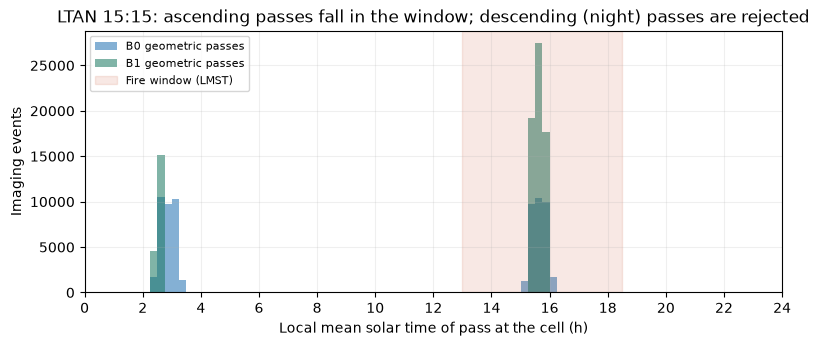

In [21]:
# Time-of-day gate: geometric passes (eta <= eta_acc) vs the LMST fire window
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.arange(0, 24.25, .25)
for lab, col in [('B0', '#1f6fb2'), ('B1', '#197760')]:
    ev = RESULTS[lab]['events']
    ax.hist(ev.lmst_h[ev.geo_ok], bins=bins, color=col, alpha=.55, label=f'{lab} geometric passes')
ax.axvspan(*FIRE_WINDOW_LMST_H, color='#c74924', alpha=.12, label='Fire window (LMST)')
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2)); ax.set_xlabel('Local mean solar time of pass at the cell (h)')
ax.set_ylabel('Imaging events'); ax.legend(fontsize=8); ax.grid(alpha=.2)
ax.set_title(f'LTAN {hhmm(LTAN_H)}: ascending passes fall in the window; descending (night) passes are rejected')
save_fig(fig, 'pass_lmst_histogram'); plt.show()

**Reading the results**

* **B0 fails R1, and the failure has a known mechanism.** Each day its usable strip covers about half the region (daily fraction plot), but the strip shifts by $\Delta\approx S/9$ from one day to the next. As §4.5 predicted, no cell is reached on all 90 days, because $W<S(1-1/k)$. A *mean* revisit near 2 days would hide this failure. That is why the requirement is written as an every-day test.
* **B1 changes the access result.** The 1-day repeat freezes the daily strip, and the centroid phasing places it over the region. Every land cell inside the usable swath is reached every afternoon. A cell is covered only if it lies within the usable half-swath (≈549 km) of the track. The region is narrower than that, so all land cells qualify (map above).
* **Local time:** every eligible pass falls well inside the LMST window for both designs. The window is therefore not the limiting condition once $T_0$ is set. The geometric limit is the R2-derived view angle.
* **⚠️ CHECK A12** — B0's nadir GSD (50.13 m) slightly exceeds R2's 50 m nadir threshold under the linear scaling assumption; R2 should be re-evaluated for B0 with the confirmed comparator GSD.
* **Coupled effect:** B1's lower altitude improves nadir GSD and raises $\eta_\text{acc}$ but shortens the geometric swath. It also raises drag, and it makes the frozen-strip benefit depend on holding the repeat altitude precisely (§10).

## 9 · Numerical accuracy checks (physical design fixed)

Following the Lecture 2 decision rule (*refine until changes are small relative to the verdict margin, and check event timing*), three independent checks are applied:

1. **Time step:** coarse bracketing step 30 s → 10 s (both $\le T/32$). Compare event counts, the largest event-time change and the metric.
2. **Spatial grid:** 0.5° → 0.25° (main) → 0.125°. Compare $F_\text{every}$ and the daily fraction.
3. **Independent calculations:**
   * Lecture coverage accounting for B0's mean access rate on the eligible branch, $f = N W/C_\phi$ per day. This should approximate B0's mean fraction of days.
   * §4.5's every-day condition $W\ge S(1-1/k)$, which predicts $F_\text{every}$ for B0 without simulation.
   * §6.1's analytic pass time $\text{LMST}=T_0+\Delta\alpha/15$ at the centroid, compared with the simulated centroid event.

In [22]:
# (1) Time-step refinement on a 0.5 deg grid (all land cells), physical design fixed
grid05 = make_grid(0.5)
rows = []
for lab, o in ORBITS.items():
    coarse = evaluate_r1(o, PAY[lab]['eta_acc_deg'], grid=grid05, step_s=30.0)
    fine = evaluate_r1(o, PAY[lab]['eta_acc_deg'], grid=grid05, step_s=10.0)
    ec, ef = coarse['events'], fine['events']
    same_count = len(ec) == len(ef)
    dt = np.abs(ec.t_s.values - ef.t_s.values).max() if same_count else np.nan
    rows.append({'Config': lab, 'Events (30 s)': len(ec), 'Events (10 s)': len(ef),
                 'Max |Δt_event| (s)': dt,
                 'F_every 30 s (%)': coarse['F_every_pct'], 'F_every 10 s (%)': fine['F_every_pct'],
                 '|ΔF_every| (pp)': abs(coarse['F_every_pct'] - fine['F_every_pct']),
                 'Nominal |margin| (pp)': abs(RESULTS[lab]['margin_pp'])})
STEP_CHECK = pd.DataFrame(rows).set_index('Config')
display(STEP_CHECK)
save_table(STEP_CHECK, 'check_timestep')

,Events (30 s),Events (10 s),Max |Δt_event| (s),F_every 30 s (%),F_every 10 s (%),|ΔF_every| (pp),Nominal |margin| (pp)
Config,,,,,,,
B0,226460,226460,0.000458,0.0,0.0,0.0,90.0
B1,228150,228150,0.000458,100.0,100.0,0.0,10.0


In [23]:
# (2) Grid refinement: 0.5, 0.25 (main), 0.125 deg
rows = []
for res in (0.5, 0.25, 0.125):
    g = GRID if res == GRID_RES_DEG else make_grid(res)
    for lab, o in ORBITS.items():
        r = RESULTS[lab] if res == GRID_RES_DEG else evaluate_r1(o, PAY[lab]['eta_acc_deg'], grid=g, keep_events=False)
        rows.append({'Grid (deg)': res, 'Land cells': int(g.land.sum()), 'Config': lab,
                     'F_every (%)': r['F_every_pct'], 'Margin (pp)': r['margin_pp'],
                     'Worst-day fraction (%)': r['daily_pct'].min(),
                     'Mean daily fraction (%)': r['daily_pct'].mean(), 'Verdict': r['verdict']})
GRID_CHECK = pd.DataFrame(rows).pivot(index='Grid (deg)', columns='Config')
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(GRID_CHECK)
save_table(GRID_CHECK, 'check_grid')

Land cells       F_every (%)         Margin (pp)         \
Config             B0    B1          B0      B1          B0     B1   
Grid (deg)                                                           
0.125            2869  2869       0.000 100.000     -90.000 10.000   
0.250             715   715       0.000 100.000     -90.000 10.000   
0.500             169   169       0.000 100.000     -90.000 10.000   

           Worst-day fraction (%)         Mean daily fraction (%)          \
Config                         B0      B1                      B0      B1   
Grid (deg)                                                                  
0.125                       2.562 100.000                  51.377 100.000   
0.250                       2.606 100.000                  51.404 100.000   
0.500                       2.317 100.000                  51.262 100.000   

           Verdict       
Config          B0   B1  
Grid (deg)               
0.125        unmet  met  
0.250        unmet  met  
0.500        unmet  met

In [24]:
# (3a) Coverage accounting (Lecture 2): mean access rate on the eligible branch, f = N W / C_phi
phi = LAT_C
C_phi = 2 * math.pi * R_E * math.cos(math.radians(phi))
for lab in ORBITS:
    o = ORBITS[lab]; N = D_SOL / o.T
    W = PAY[lab]['usable_swath_km']
    f = N * W / C_phi
    print(f'{lab}: N = {N:.4f} revs/day, W = {W:.1f} km, C_phi = {C_phi:.0f} km  ->  f = NW/C = {f:.3f} per day; '
          f'simulated mean fraction of days = {RESULTS[lab]["mean_frac_days"]:.3f}')
print('(B1 is a frozen strip: its mean depends on placement, so NW/C is not a prediction for it.)')

# (3b) Every-day condition W >= S (1 - 1/k)
for lab in ORBITS:
    o = ORBITS[lab]; N = o.j / o.k
    S = C_phi / N; need = S * (1 - 1 / o.k)
    W = PAY[lab]['usable_swath_km']
    print(f'{lab}: daily spacing S = {S:.0f} km, cycle spacing Δ = {C_phi/o.j:.0f} km, '
          f'need W >= {need:.0f} km, have W = {W:.0f} km -> '
          f'{"every-day access possible in a strip" if W >= need else "no cell reached every day (predict F_every = 0)"}; '
          f'simulated F_every = {RESULTS[lab]["F_every_pct"]:.2f} %')

# (3c) Analytic pass LMST at the centroid vs simulation
for lab, o in ORBITS.items():
    dalpha, _ = delta_alpha_deg(LAT_C, o.inc_deg)
    ev = imaging_events(o, LAT_C, LON_C, horizon_s=(0.0, 2 * D_SOL))
    first = ev[ev.ascending & (ev.elev_deg > 0)].sort_values('eta_deg').iloc[0]   # the overhead (closest) pass
    print(f'{lab}: analytic LMST = T0 + Δα/15 = {hhmm(LTAN_H + dalpha/15)} '
          f'({(LTAN_H + dalpha/15)*60:.2f} min) | simulated {first.lmst_h*60:.2f} min, eta = {first.eta_deg:.4f}°')

B0: N = 14.8889 revs/day, W = 1097.0 km, C_phi = 32480 km  ->  f = NW/C = 0.503 per day; simulated mean fraction of days = 0.514
B1: N = 15.0000 revs/day, W = 1098.1 km, C_phi = 32480 km  ->  f = NW/C = 0.507 per day; simulated mean fraction of days = 1.000
(B1 is a frozen strip: its mean depends on placement, so NW/C is not a prediction for it.)
B0: daily spacing S = 2181 km, cycle spacing Δ = 242 km, need W >= 1939 km, have W = 1097 km -> no cell reached every day (predict F_every = 0); simulated F_every = 0.00 %
B1: daily spacing S = 2165 km, cycle spacing Δ = 2165 km, need W >= 0 km, have W = 1098 km -> every-day access possible in a strip; simulated F_every = 100.00 %
B0: analytic LMST = T0 + Δα/15 = 15:38 (937.71 min) | simulated 937.71 min, eta = 0.0000°
B1: analytic LMST = T0 + Δα/15 = 15:37 (937.31 min) | simulated 937.31 min, eta = 0.0000°


**Interpretation.** Each check is judged against the verdict margin. The time-step change moves event times by milliseconds, far below the minutes of local-time margin, and does not change $F_\text{every}$. Grid refinement changes the land mask at the coast and the cells at the swath edge; $F_\text{every}$ is unchanged and the worst-day fraction moves by less than 0.3 percentage points. That is small compared with B0's margin ($-90$ pp) and B1's margin. **Neither limiting verdict depends on the numerical settings.** The analytic checks reproduce B0's mean rate and its zero every-day fraction, and the centroid pass time to within a fraction of a minute, before any simulation result is used.

What the checks do **not** validate is the physical model itself: the Keplerian rather than the nodal period, drag, short-period $J_2$ and the spherical Earth. Those limits are the subject of §10.

## 10 · Lifetime, orbit maintenance and the extension parameter

### 10.1 Design lifetime
> **⚠️ CHECK A26** — The design lifetime was undefined in D1. Five years is a placeholder that needs a justification (seasons required, comparator design life, propellant for drag make-up, deorbit compliance).

**Design lifetime: 5 years** (assumed). This covers five peak seasons (Dec 2026 – Feb 2031). It is the period over which R1 must be *maintained*. The access analysis above covers **one 90-day season** of nominal orbit. The verdicts hold only for an orbit kept at its repeat altitude and LTAN. They say nothing about the uncontrolled orbit over 5 years.

### 10.2 Why B1 must be held tightly (drift sensitivity)
If the altitude is off by $\delta h$, the period changes, and the 1-day track no longer closes. The `eo.repeat_diagnostics` helper gives the signed node misclosure after one cycle. Inclination is held at its nominal value, so this is an injection/decay error rather than a retuned orbit:
$$\delta\lambda_\text{day} = 360^\circ k - j\,(\omega_\oplus-\dot\Omega)\,T\ \ \text{(wrapped)},\qquad \delta x_\phi \approx R_E\,\delta\lambda_\text{day}\cos\phi\ \text{per day}.$$
Because $j=15$ revolutions accumulate the period error every day, a 1 km error moves B1's strip by several km per day. Over the season it walks off the region.

Using B1's simulated cross-track offset of each land cell from its day-0 track, we find the strip shift $s$ (east or west) at which the reached land fraction first falls below 90 %. Dividing by the drift rate gives **how many days an uncorrected altitude error can persist**. This is the quantitative basis for choosing the *altitude* (equivalently, the ground-track phase) as the extension parameter, and for a control band.

> **⚠️ CHECK A28** — The strip drift is treated as a pure cross-track shift with inclination held at nominal; days-to-failure values are estimates.

B1 strip-shift tolerance before R1 fails: 230 km east, 218 km west


,"Track drift (km/day at centroid lat, east +)",LTAN drift (min per 90 d),Days until R1 fails (uncorrected),Season drift (km)
Altitude error δh (km),,,,
-2.00,14.12,0.36,16.29,1270.69
-1.00,7.06,0.18,32.58,635.37
-0.50,3.53,0.09,65.16,317.69
-0.10,0.71,0.02,325.79,63.54
0.10,-0.71,-0.02,308.79,-63.54
0.50,-3.53,-0.09,61.76,-317.70
1.00,-7.06,-0.18,30.88,-635.41
2.00,-14.12,-0.36,15.44,-1270.86


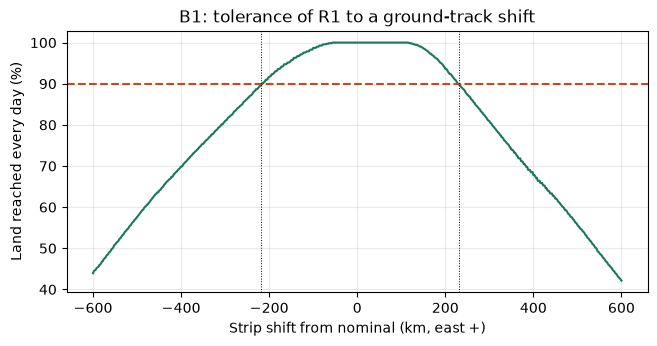

In [25]:
# Cross-track offset of each land cell from the B1 track on day 0 (eligible-geometry events)
ev = RESULTS['B1']['events']
d0 = (ev[(ev.local_day == 0) & ev.ascending & (ev.elev_deg > 0)]
      .sort_values('eta_deg').groupby('cell').first())          # nearest (smallest view angle) day-0 track
cell_x = d0.cross_km.reindex(LAND.index)                        # NaN if no ascending pass on day 0 (not expected)
w = LAND.area_km2.values
reach = PAY['B1']['reach_km']

def reached_fraction(shift_km):
    # Land fraction still inside the usable strip after shifting the strip by shift_km (east +)
    inside = np.abs(cell_x.values - shift_km) <= reach
    return 100 * w[inside].sum() / w.sum()

shifts = np.arange(-600, 601, 2.0)
frac = np.array([reached_fraction(s) for s in shifts])
east_tol = shifts[(shifts >= 0) & (frac < REQUIRED_PCT)].min()
west_tol = -shifts[(shifts <= 0) & (frac < REQUIRED_PCT)].max()
print(f'B1 strip-shift tolerance before R1 fails: {east_tol:.0f} km east, {west_tol:.0f} km west')

rows = []
for dh in (-2.0, -1.0, -0.5, -0.1, 0.1, 0.5, 1.0, 2.0):   # CHECK A27: range not yet sourced
    diag = eo.repeat_diagnostics(B1.h_km + dh, B1.j, B1.k, adjust_sso=False, fixed_inc_deg=B1.inc_deg)
    drift_km_day = diag['node_error_km'] * math.cos(math.radians(LAT_C)) / B1.k     # east +, along parallel
    tol = east_tol if drift_km_day > 0 else west_tol
    rows.append({'Altitude error δh (km)': dh,
                 'Track drift (km/day at centroid lat, east +)': drift_km_day,
                 'LTAN drift (min per 90 d)': diag['ltan_drift_min_per_day'] * N_DAYS,
                 'Days until R1 fails (uncorrected)': tol / abs(drift_km_day),
                 'Season drift (km)': drift_km_day * N_DAYS})
DRIFT = pd.DataFrame(rows).set_index('Altitude error δh (km)')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(DRIFT)
save_table(DRIFT, 'B1_altitude_drift_sensitivity')

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(shifts, frac, color='#197760'); ax.axhline(REQUIRED_PCT, color='#c74924', ls='--')
ax.axvline(east_tol, color='k', lw=.7, ls=':'); ax.axvline(-west_tol, color='k', lw=.7, ls=':')
ax.set_xlabel('Strip shift from nominal (km, east +)'); ax.set_ylabel('Land reached every day (%)')
ax.set_title('B1: tolerance of R1 to a ground-track shift'); ax.grid(alpha=.25)
save_fig(fig, 'B1_shift_tolerance'); plt.show()

**Implications for robustness and the extension investigation:**

* B1's R1 pass depends on **holding the ground track**. An uncorrected altitude error of a few hundred metres uses up the margin within one season. The design response is a **ground-track control band**, with drag make-up manoeuvres timed to keep the strip within the east/west tolerance above, as in the Landsat example (Lecture 3).
* B0 does not have this sensitivity, but it fails R1 nominally. Altitude errors cannot make it pass, because $W < S(1-1/k)$ for any $k\ge2$ cycle.
* **Suggested extension parameter: initial altitude error / ground-track phase**, applied to both designs over the same range. A range spanning ±0.1 to ±2 km brackets the transition from "maintained" to "fails within the season". **⚠️ CHECK A27** — The endpoints are not yet sourced; they are to be tied to launch-injection accuracy and drag-decay rates. The full test reruns `evaluate_r1` on an offset orbit (`replace(B1, h_km=B1.h_km + dh)`) *without* retuning inclination or re-phasing, and is reported separately from this nominal analysis.

## 11 · STM entries for R1

The table below collects R1's STM fields for both configurations. The selected design's row is the one carried into the final STM.

In [26]:
def stm_row(lab):
    r, o = RESULTS[lab], ORBITS[lab]
    return {
        'ID / objective': 'R1 / O1 (detect & locate active fires, VIC + southern NSW)',
        'Requirement & source': (f'≥1 eligible access per local day for ≥{REQUIRED_PCT:.0f}% of land-cell area, '
                                 f'{hhmm(FIRE_WINDOW_LMST_H[0])}–{hhmm(FIRE_WINDOW_LMST_H[1])} LMST, every day '
                                 f'{EPOCH_UTC.date()} + {N_DAYS} d. Assumed; window from diurnal fire cycle (Giglio 2007).'),
        'Design response': (f'{lab}: SSO {o.j} revs/{o.k} d, h = {o.h_km:.2f} km, i = {o.inc_deg:.3f}°, '
                            f'LTAN {hhmm(LTAN_H)}; fixed nadir pushbroom, η_acc = {r["eta_acc_deg"]:.2f}° '
                            f'(R2 100 m GSD limit), W = {PAY[lab]["usable_swath_km"]:.0f} km; centroid-phased.'),
        'Performance & evidence': (f'F_every = {r["F_every_pct"]:.2f}%; worst day {r["daily_pct"].min():.1f}%, '
                                   f'mean day {r["daily_pct"].mean():.1f}%. orbit_planning.ipynb §8; circular Kepler + '
                                   f'secular J2, epoch {EPOCH_UTC:%Y-%m-%d %H:%M} UTC, {GRID_RES_DEG}° grid.'),
        'Margin & verdict': f'{r["margin_pp"]:+.2f} pp; {r["verdict"]} (geometric access, stated period)',
        'Robustness & limitations': ('Strip drift under altitude error (§10); maintained orbit assumed. Cloud/smoke, '
                                     'tasking, drag, nodal period and usable imagery not evaluated.'),
    }

STM_R1 = pd.DataFrame({lab: stm_row(lab) for lab in ORBITS})
with pd.option_context('display.max_colwidth', None):
    display(STM_R1)
save_table(STM_R1, 'STM_R1_rows')

,B0,B1
ID / objective,"R1 / O1 (detect & locate active fires, VIC + southern NSW)","R1 / O1 (detect & locate active fires, VIC + southern NSW)"
Requirement & source,"≥1 eligible access per local day for ≥90% of land-cell area, 13:00–18:30 LMST, every day 2026-12-01 + 90 d. Assumed; window from diurnal fire cycle (Giglio 2007).","≥1 eligible access per local day for ≥90% of land-cell area, 13:00–18:30 LMST, every day 2026-12-01 + 90 d. Assumed; window from diurnal fire cycle (Giglio 2007)."
Design response,"B0: SSO 134 revs/9 d, h = 601.54 km, i = 97.794°, LTAN 15:15; fixed nadir pushbroom, η_acc = 41.23° (R2 100 m GSD limit), W = 1097 km; centroid-phased.","B1: SSO 15 revs/1 d, h = 567.03 km, i = 97.659°, LTAN 15:15; fixed nadir pushbroom, η_acc = 42.87° (R2 100 m GSD limit), W = 1098 km; centroid-phased."
Performance & evidence,"F_every = 0.00%; worst day 2.6%, mean day 51.4%. orbit_planning.ipynb §8; circular Kepler + secular J2, epoch 2026-12-01 00:00 UTC, 0.25° grid.","F_every = 100.00%; worst day 100.0%, mean day 100.0%. orbit_planning.ipynb §8; circular Kepler + secular J2, epoch 2026-12-01 00:00 UTC, 0.25° grid."
Margin & verdict,"-90.00 pp; unmet (geometric access, stated period)","+10.00 pp; met (geometric access, stated period)"
Robustness & limitations,"Strip drift under altitude error (§10); maintained orbit assumed. Cloud/smoke, tasking, drag, nodal period and usable imagery not evaluated.","Strip drift under altitude error (§10); maintained orbit assumed. Cloud/smoke, tasking, drag, nodal period and usable imagery not evaluated."


### Limitations
See §0 for the full assumptions register; the main limitations are:
* **Model:** spherical Earth, circular Keplerian period (not the $J_2$ nodal period), secular $J_2$ node only, no drag. Real repeat altitudes differ by a few km from the catalogue values, and orbit maintenance is assumed.
* **Eligibility is geometric access** with the R2-derived view-angle gate. It does *not* establish detection: cloud, smoke opacity, fire size and radiometric detection are R2/payload questions.
* **Cell-centre** access on a 1:50 M land mask. Results are area-weighted estimates, not exact area unions.
* **Mean solar time:** the equation of time and the cell's elevation above the ellipsoid are neglected. Both are small compared with the pass-time margins.
* **Delivery/contact (D1 R4)** is not evaluated (⚠️ CHECK A30).
* **One season, one epoch.** Because the SSO holds the LTAN, other seasons give the same geometry. Only the maintained-orbit assumption limits extending the verdict over the 5-year lifetime.